# Competitive landscape

## Configuration

In [3]:
import re
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy import stats                      # linear regression (Lotka) and Kendall's tau
from sqlalchemy import case, func, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # applications
    TLS202_APPLN_TITLE,         # titles
    TLS203_APPLN_ABSTR,         # abstracts
    TLS206_PERSON,              # persons: standardised name, sector, country
    TLS207_PERS_APPLN,          # person <-> application links (applicant / inventor)
    TLS209_APPLN_IPC,           # IPC classification
    TLS211_PAT_PUBLN,           # publications: grants and their dates
    TLS224_APPLN_CPC,           # CPC classification
)

# ---------------------------------------------------------------- environment
ENV = "PROD"                         # matches the PATSTAT environment used to build the CSV dataset
OUTPUT_DIR = Path("outputs/step2")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- applicant names (Section 2)
NAME_METHOD = "dictionary"           # "psn" (PATSTAT names as they are), "dictionary" or "cleanco"
GOLD_STANDARD_FILE = "PATSTAT_500_label_datav4.csv"   # hand-labelled names (Section 2.4), in the same folder as this notebook

# ---------------------------------------------------------------- replication (Section 4): benchmark paper example
REPL_OFFICE = "US"                                      # USPTO patents...
REPL_GRANTED = (date(1976, 1, 1), date(2002, 12, 31))   # ...granted between these two dates
REPL_KEYWORDS = ("fuel cell",)                          # searched in titles and abstracts
REPL_CLASSES = ("H01M8",)                               # IPC/CPC H01M 8: fuel cells
REPL_SELECTION = "keywords or classes"                  # "keywords", "classes" or "keywords or classes"
PAPER_COUNTRIES = ("AU", "CA", "FR", "DE", "IL", "IT", "JP", "NL", "SE", "CH", "GB", "US")

# ---------------------------------------------------------------- your sector (Section 5): defined by your CSV
CSV_FILE = Path("utility_scale_storage_reviewed_adaptive_V2.csv")
SECTOR_NAME = "Utility-Scale Energy Storage"
YEAR_MIN, YEAR_MAX = 2001, 2025
LAST_COMPLETE_YEAR = YEAR_MAX - 3    # the last 3 priority years are still incomplete in PATSTAT
IPR_TYPE = "PI"                      # patents of invention only
SPLIT_YEAR = 2015                    # incumbents file before SPLIT_YEAR, entrants from SPLIT_YEAR on
WINDOW = 3                           # years per window when following concentration over time
TOP_N = 15                           # rows in the tables of top applicants

COUNTRY_NAMES = {
    "AU": "Australia", "CA": "Canada", "FR": "France", "DE": "Germany",
    "IL": "Israel", "IT": "Italy", "JP": "Japan", "NL": "Netherlands",
    "SE": "Sweden", "CH": "Switzerland", "GB": "UK", "US": "USA",
    "CN": "China", "KR": "South Korea", "ES": "Spain", "DK": "Denmark",
}

patstat = PatstatClient(env=ENV)
db = patstat.orm()

# ---------------------------------------------------------------- load reviewed CSV dataset in memory

df_csv = pd.read_csv(CSV_FILE)
col_map = {c.strip().lower(): c for c in df_csv.columns}
SECTOR_FAMILY_IDS = df_csv[col_map["docdb_family_id"]].dropna().astype(int).unique().tolist()

# Single query on TLS201_APPLN to retrieve all member applications for our DOCDB families
q = (
    db.query(
        TLS201_APPLN.appln_id,
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_auth,
        TLS201_APPLN.appln_filing_year,
        TLS201_APPLN.earliest_filing_year,
        TLS201_APPLN.ipr_type,
        TLS201_APPLN.granted,
        TLS201_APPLN.docdb_family_size,
        TLS201_APPLN.nb_applicants,
        TLS201_APPLN.nb_inventors,
    )
    .filter(TLS201_APPLN.docdb_family_id.in_(SECTOR_FAMILY_IDS))
)

df_utility = patstat.df(q).drop_duplicates(subset=["appln_id"])
SECTOR_APPLN_IDS = df_utility["appln_id"].dropna().astype(int).unique().tolist()

print(
    f"Loaded {CSV_FILE.name} | DOCDB families: {len(SECTOR_FAMILY_IDS):,} | "
    f"Applications: {len(SECTOR_APPLN_IDS):,}"
)

Loaded utility_scale_storage_reviewed_adaptive_V2.csv | DOCDB families: 6,838 | Applications: 8,649


## Harmonization

### Starting Harmonizarion

In [4]:
#Locate and inspect the gold-standard CSV file
gs_path = Path("PATSTAT_500_label_datav4.csv")

df_gs = pd.read_csv(gs_path)
print("Columns:", df_gs.columns.tolist(), "| Rows:", len(df_gs))
display(df_gs.head(15))

# Filter rows containing common legal suffixes (e.g., S.p.A., AG, INC, LTD) to check label conventions
mask_legal = df_gs.apply(
    lambda col: col.astype(str).str.contains(r"\b(?:S\.?P\.?A\.?|AG|INC|LTD)\b", case=False, regex=True)
).any(axis=1)
display(df_gs[mask_legal].head(15))

Columns: ['Group', 'comp'] | Rows: 3192


,Group,comp
0,1,NOKIA CORPORATION
1,1,NOKIA (DEUTSCHLAND)
2,1,NOKIA GRAETZ
3,2,NOKIA SIEMENS NETWORKS SCHWEIZ
4,1,NOKIA
5,1,NOKIA MOBILE PHONES (U.K.) LIMITED
6,2,NOKIA SIEMENS NETWORKS S.P.A.
7,2,NOKIA SIEMENS NETWORKS
8,1,NOKIA COMMUNICATION
9,1,NOKIA HIGH SPEED ACCESS PRODUCTS


,Group,comp
6,2,NOKIA SIEMENS NETWORKS S.P.A.
244,9,SONY ELECTRONICS INC. (A DELAWARE CORPORATION)
337,11,"SANOFI (CHINA) INVESTMENT CO., LTD. SHANGHAI B..."
355,12,STMICROELECTRONICS LTD (MALTA)
555,23,IBM CANADA LTD./LTEE
604,45,"ORACLE AMERICA, INC. FORMERLY KNOWN AS SUN MIC..."
657,63,"EXXONMOBIL CHEMICAL PATENTS, INC., A CORPORATI..."
713,74,"UNITED PARCEL SERVICE OF AMERICA, INC., DOING ..."
727,88,"LEXMARK INTERNATIONAL, INC., INTELLECTUAL PROP..."
814,151,COMERCIALIZADORA KRAVIVA S.P.A.


In [5]:
%pip install -q cleanco


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
from cleanco import basename as cleanco_basename

# 1. Fetch applicant records for all applications in our dataset (single query, 8,649 IDs)
q = (
    db.query(
        TLS207_PERS_APPLN.appln_id,
        TLS207_PERS_APPLN.person_id,
        TLS207_PERS_APPLN.applt_seq_nr,
        TLS206_PERSON.person_name,
        TLS206_PERSON.doc_std_name,
        TLS206_PERSON.psn_name,
        TLS206_PERSON.han_name,
        TLS206_PERSON.person_ctry_code,
        TLS206_PERSON.psn_sector,
    )
    .join(TLS206_PERSON, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
    .filter(TLS207_PERS_APPLN.appln_id.in_(SECTOR_APPLN_IDS))
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0)
)

df_applicants = patstat.df(q).merge(
    df_utility[["appln_id", "docdb_family_id", "appln_auth", "earliest_filing_year"]],
    on="appln_id",
    how="inner",
)

# 2. Define legal suffixes and safe organizational tail words 
LEGAL_SUFFIXES = {
    "INC", "INCORPORATED", "CORP", "CORPORATION", "CO", "COMPANY", "LTD", "LIMITED",
    "LLC", "LP", "PLC", "GMBH", "AG", "KG", "MBH", "SE", "SA", "SAS", "SPA", "SRL",
    "SARL", "BV", "BVBA", "NV", "AB", "AS", "ASA", "OY", "OYJ", "KK", "KABUSHIKI",
    "KAISHA", "LTDA", "PTY", "PVT", "BHD", "SDN", "LTEE", "LIMITEE", "THE",
    "AKTIENGESELLSCHAFT", "GESELLSCHAFT",
}

ORG_TAILS = {"BRANCH", "DIV", "DIVISION", "GROUP", "HOLDING", "HOLDINGS"}

# Optional manual dictionary for major players / post-cleaning residual variants
MANUAL_ALIASES = {
    "STATE GRID CORPORATION OF CHINA": "SGCC",
    "STATE GRID CORP CHINA": "SGCC",
    "CHINA ELECTRIC POWER RESEARCH INSTITUTE": "SGCC",
    "GENERAL ELECTRIC": "GE",
    "GENERAL ELECTRIC COMPANY": "GE",
    "LG ENERGY SOLUTION": "LG",
    "LG CHEM": "LG",
}


def harmonise_applicant_name(row):
    # Prefer psn_name, fallback to han_name or raw person_name
    raw = row["psn_name"]
    if pd.isna(raw) or not str(raw).strip():
        raw = row["han_name"] if pd.notna(row["han_name"]) and str(row["han_name"]).strip() else row["person_name"]

    s = str(raw).upper().strip()

    # Step 1: Cut secondary relational clauses and parenthetical notes
    s = re.split(r"\b(?:C/O|DBA|DOING BUSINESS AS|FORMERLY KNOWN AS|FORMERLY|F/K/A)\b", s, maxsplit=1)[0]
    s = re.sub(r"\([^)]*\)", " ", s)

    # Step 2: Strip dotted/international legal forms via cleanco, then normalize punctuation
    s = str(cleanco_basename(s)).upper()
    words = re.sub(r"[^A-Z0-9 ]", " ", s).split()

    # Remove leading legal words (e.g., KABUSHIKI KAISHA TOSHIBA)
    while len(words) > 1 and words[0] in LEGAL_SUFFIXES:
        words.pop(0)

    # Remove trailing legal suffixes and generic organizational tails
    removable = LEGAL_SUFFIXES | ORG_TAILS
    while len(words) > 1 and words[-1] in removable:
        words.pop()

    cleaned = " ".join(words) if words else str(raw).upper().strip()

    # Step 3: Apply curated manual overrides
    return MANUAL_ALIASES.get(cleaned, cleaned)


df_applicants["clean_applicant"] = df_applicants.apply(harmonise_applicant_name, axis=1)

# 3. Inspect Top 25 consolidated applicants and verify merged raw variants
top_check = (
    df_applicants.groupby("clean_applicant", as_index=False)
    .agg(
        families=("docdb_family_id", "nunique"),
        applications=("appln_id", "nunique"),
        raw_variants=("person_name", "nunique"),
        sample_raw=("person_name", lambda x: " | ".join(sorted(set(x.dropna()))[:3])),
    )
    .sort_values(["families", "applications"], ascending=False)
    .head(25)
    .reset_index(drop=True)
)

display(top_check)

,clean_applicant,families,applications,raw_variants,sample_raw
0,SGCC,418,428,12,CHINA ELECTRIC POWER RESEARCH INSTITUTE | CHIN...
1,XIAN THERMAL POWER RESEARCH INSTITUTE,156,163,2,"XI'AN THERMAL POWER RESEARCH INSTITUTE CO., LT..."
2,NORTH CHINA ELECTRIC POWER UNIVERSITY,151,155,6,NORTH CHINA ELECTRIC POWER UNIVERSITY | NORTH ...
3,TSINGHUA UNIVERSITY,133,139,6,SICHUAN ENERGY INTERNET RESEARCH INSTITUTE OF ...
4,GUANGDONG POWER GRID,78,81,21,DONGGUAN POWER BUREAU OF GUANGDONG POWER GRID ...
5,HUANENG CLEAN ENERGY RESEARCH INSTITUTE,61,64,1,HUANENG CLEAN ENERGY RESEARCH INSTITUTE
6,CHINA THREE GORGES,58,60,1,CHINA THREE GORGES CORPORATION
7,CHINESE ACADEMY OF SCIENCES,54,61,9,"GUANGZHOU INSTITUTE OF ENERGY CONVERSION, CHIN..."
8,SUNGROW POWER SUPPLY,51,62,3,"SUNGROW POWER SUPPLY (NANJING) CO., LTD. | SUN..."
9,STATE GRID SHANGHAI MUNICIPAL ELECTRIC POWER,44,44,1,STATE GRID SHANGHAI MUNICIPAL ELECTRIC POWER C...


In [7]:
CONSOLIDATE_CORPORATE_GROUPS = True  # Set False to keep provincial subsidiaries separate

GROUP_ALIASES = {
    "GUANGDONG POWER GRID": "CSG (CHINA SOUTHERN POWER GRID)",
    "GUIZHOU POWER GRID": "CSG (CHINA SOUTHERN POWER GRID)",
    "YUNNAN POWER GRID": "CSG (CHINA SOUTHERN POWER GRID)",
    "GUANGXI POWER GRID": "CSG (CHINA SOUTHERN POWER GRID)",
    "HAINAN POWER GRID": "CSG (CHINA SOUTHERN POWER GRID)",
    "ELECTRIC POWER RESEARCH INSTITUTE CSG": "CSG (CHINA SOUTHERN POWER GRID)",
    "NINGDE CONTEMPORARY AMPEREX TECHNOLOGY": "CATL (NINGDE CONTEMPORARY AMPEREX)",
    "XIAMEN HAICHEN ENERGY STORAGE TECHNOLOGY": "HITHIUM (XIAMEN HAICHEN)",
}


def refine_applicant_name(name):
    "Consolidate residual State Grid / CSG subsidiaries and standardized brand names."
    s = re.sub(r"\bCO\s+LTD\b", " ", str(name)).strip()
    s = " ".join(s.split())

    if CONSOLIDATE_CORPORATE_GROUPS:
        if "STATE GRID" in s or "STATE GRI" in s:
            return "SGCC"
        if s.endswith(" CSG") or s.startswith("CSG "):
            return "CSG (CHINA SOUTHERN POWER GRID)"
        if s in GROUP_ALIASES:
            return GROUP_ALIASES[s]

    return s


df_applicants["clean_applicant"] = df_applicants["clean_applicant"].map(refine_applicant_name)

display(
    df_applicants.groupby("clean_applicant", as_index=False)
    .agg(families=("docdb_family_id", "nunique"), applications=("appln_id", "nunique"))
    .sort_values(["families", "applications"], ascending=False)
    .reset_index(drop=True)
)

,clean_applicant,families,applications
0,SGCC,1008,1027
1,CSG (CHINA SOUTHERN POWER GRID),168,171
2,XIAN THERMAL POWER RESEARCH INSTITUTE,156,163
3,NORTH CHINA ELECTRIC POWER UNIVERSITY,151,155
4,TSINGHUA UNIVERSITY,133,139
...,...,...,...
3541,西门子公司,1,1
3542,西门子歌美飒可再生能源有限两合公司,1,1
3543,霍尼韦尔国际公司,1,1
3544,麦哲伦&巴伦支私人有限公司,1,1


In [8]:
import unicodedata

# 1. Quick diagnostic on non-ASCII applicant records in the dataset
non_ascii_mask = ~df_applicants["clean_applicant"].map(lambda x: str(x).isascii())
print(
    f"Non-ASCII rows: {non_ascii_mask.sum()} / {len(df_applicants)} | "
    f"Distinct families affected: {df_applicants.loc[non_ascii_mask, 'docdb_family_id'].nunique()}"
)

# 2. CJK legal suffixes (ordered longest-first so compound forms are stripped completely)
CJK_LEGAL_SUFFIXES = (
    "有限两合公司", "股份有限公司", "有限责任公司", "集团有限公司",
    "私人有限公司", "有限公司", "责任公司", "集团公司", "公司",
    "株式会社", "有限会社", "合同会社",
)

# Common Chinese transliterations of major international firms appearing in storage filings
CJK_ALIASES = {
    "西门子": "SIEMENS",
    "西门子歌美飒可再生能源": "SIEMENS GAMESA RENEWABLE ENERGY",
    "霍尼韦尔国际": "HONEYWELL INTERNATIONAL",
    "霍尼韦尔": "HONEYWELL",
    "通用电气": "GE",
    "松下": "PANASONIC",
    "三星": "SAMSUNG",
    "特斯拉": "TESLA",
    "宁德时代新能源科技": "CATL (NINGDE CONTEMPORARY AMPEREX)",
    "比亚迪": "BYD",
    "华为技术": "HUAWEI TECHNOLOGIES",
    "华为数字能源技术": "HUAWEI DIGITAL POWER TECHNOLOGIES",
    "国家电网": "SGCC",
    "中国南方电网": "CSG (CHINA SOUTHERN POWER GRID)",
}


def harmonise_with_cjk(row):
    "Clean applicant names handling Unicode full-width characters, PATSTAT Latin fallbacks, and CJK suffixes."
    # Prefer psn_name, fallback to han_name or person_name
    candidates = [row["psn_name"], row["doc_std_name"], row["han_name"], row["person_name"]]
    valid = [str(c).strip() for c in candidates if pd.notna(c) and str(c).strip()]
    if not valid:
        return "UNKNOWN"

    raw = valid[0]
    # If primary name has CJK characters, check if doc_std_name or han_name already provides a Latin version
    if not unicodedata.normalize("NFKC", raw).isascii():
        latin_alt = next(
            (c for c in valid[1:] if unicodedata.normalize("NFKC", c).isascii()),
            None,
        )
        if latin_alt:
            raw = latin_alt

    # Step 1: Normalize full-width characters (e.g., ＡＵＲＡ -> AURA) and uppercase
    s = unicodedata.normalize("NFKC", raw).upper().strip()

    # Step 2: Cut secondary relational clauses and parenthetical notes
    s = re.split(r"\b(?:C/O|DBA|DOING BUSINESS AS|FORMERLY KNOWN AS|FORMERLY|F/K/A)\b", s, maxsplit=1)[0]
    s = re.sub(r"\([^)]*\)", " ", s).strip()

    # Step 3: Strip trailing CJK legal suffixes (e.g., 株式会社, 有限公司, 公司)
    changed = True
    while changed:
        changed = False
        for suffix in CJK_LEGAL_SUFFIXES:
            if s.endswith(suffix) and len(s) > len(suffix):
                s = s[: -len(suffix)].strip()
                changed = True

    # Step 4: If purely CJK remains, check targeted corporate aliases
    if not s.isascii():
        s_compact = re.sub(r"\s+", "", s)
        if s_compact in CJK_ALIASES:
            return refine_applicant_name(CJK_ALIASES[s_compact])

    # Step 5: Apply cleanco and standard Latin token cleaning
    s = str(cleanco_basename(s)).upper()
    words = re.sub(r"[^A-Z0-9 ]", " ", s).split()

    while len(words) > 1 and words[0] in LEGAL_SUFFIXES:
        words.pop(0)
    removable = LEGAL_SUFFIXES | ORG_TAILS
    while len(words) > 1 and words[-1] in removable:
        words.pop()

    cleaned = " ".join(words) if words else s
    cleaned = MANUAL_ALIASES.get(cleaned, cleaned)
    return refine_applicant_name(cleaned)


df_applicants["clean_applicant"] = df_applicants.apply(harmonise_with_cjk, axis=1)

# Verify how the previously problematic CJK rows were resolved
display(
    df_applicants.loc[non_ascii_mask, ["person_name", "doc_std_name", "clean_applicant"]]
    .drop_duplicates()
    .head(20)
)

Non-ASCII rows: 38 / 11691 | Distinct families affected: 36


,person_name,doc_std_name,clean_applicant
761,麦哲伦&巴伦支私人有限公司,麦哲伦&巴伦支私人有限公司,麦哲伦&巴伦支
1428,埃内欧储能系统有限公司,埃内欧储能系统有限公司,埃内欧储能系统
1801,日立能源有限公司,日立能源有限公司,日立能源
1902,ヌオーヴォ ピニォーネ ソチエタ レスポンサビリタ リミタータＮＵＯＶＯ ＰＩＧＮＯＮＥ Ｓ...,ヌオーヴォ ピニォーネ ソチエタ レスポンサビリタ リミタータＮＵＯＶＯ ＰＩＧＮＯＮＥ Ｓ...,NUOVO PIGNONE
3060,マゼラン アンド バレンツ， エス．エル．ＭＡＧＥＬＬＡＮ ＆ ＢＡＲＥＮＴＳ， Ｓ．Ｌ．,マゼラン アンド バレンツ， エス．エル．ＭＡＧＥＬＬＡＮ ＆ ＢＡＲＥＮＴＳ， Ｓ．Ｌ．,MAGELLAN BARENTS
3782,テンポラル・パワー・リミテッドＴＥＭＰＯＲＡＬ ＰＯＷＥＲ ＬＴＤ．,テンポラル・パワー・リミテッドＴＥＭＰＯＲＡＬ ＰＯＷＥＲ ＬＴＤ．,TEMPORAL POWER
4320,ＡＵＲＡ－Ｇｒｅｅｎ Ｅｎｅｒｇｙ株式会社,ＡＵＲＡ－ＧＲＥＥＮ ＥＮＥＲＧＹ株式会社,AURA GREEN ENERGY
4883,西门子公司,西门子公司,SIEMENS
4972,株式会社ＧＳユアサ,株式会社ＧＳユアサ,GS
5549,维斯塔斯风力系统集团公司,维斯塔斯风力系统集团公司,维斯塔斯风力系统


### Final harmonization

In [9]:
import re
import unicodedata
import pandas as pd
from cleanco import basename as cleanco_basename


# ---------------------------------------------------------------- 1. Fetch applicant records from PATSTAT
year_col = "earliest_filing_year" if "earliest_filing_year" in df_utility.columns else "appln_filing_year"

q = (
    db.query(
        TLS207_PERS_APPLN.appln_id,
        TLS207_PERS_APPLN.person_id,
        TLS207_PERS_APPLN.applt_seq_nr,
        TLS206_PERSON.person_name,
        TLS206_PERSON.doc_std_name,
        TLS206_PERSON.psn_name,
        TLS206_PERSON.han_name,
        TLS206_PERSON.person_ctry_code,
        TLS206_PERSON.psn_sector,
    )
    .join(TLS206_PERSON, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
    .filter(TLS207_PERS_APPLN.appln_id.in_(SECTOR_APPLN_IDS))
    .filter(TLS207_PERS_APPLN.applt_seq_nr > 0)  # applicants only
)

df_applicants = patstat.df(q).merge(
    df_utility[["appln_id", "docdb_family_id", "appln_auth", year_col]].drop_duplicates(subset=["appln_id"]),
    on="appln_id",
    how="inner",
)

# ---------------------------------------------------------------- 2. Configuration & domain dictionaries
CONSOLIDATE_CORPORATE_GROUPS = True  # Set False to keep provincial subsidiaries separate from parent groups

LEGAL_SUFFIXES = {
    "INC", "INCORPORATED", "CORP", "CORPORATION", "CO", "COMPANY", "LTD", "LIMITED",
    "LLC", "LP", "PLC", "GMBH", "AG", "KG", "MBH", "SE", "SA", "SAS", "SPA", "SRL",
    "SARL", "BV", "BVBA", "NV", "AB", "AS", "ASA", "OY", "OYJ", "KK", "KABUSHIKI",
    "KAISHA", "LTDA", "PTY", "PVT", "BHD", "SDN", "LTEE", "LIMITEE", "THE",
    "AKTIENGESELLSCHAFT", "GESELLSCHAFT",
}

ORG_TAILS = {"BRANCH", "DIV", "DIVISION", "GROUP", "HOLDING", "HOLDINGS"}

CJK_LEGAL_SUFFIXES = (
    "有限两合公司", "股份有限公司", "有限责任公司", "集团有限公司",
    "私人有限公司", "有限公司", "责任公司", "集团公司", "公司",
    "株式会社", "有限会社", "合同会社",
)

# Direct mapping for non-ASCII / CJK / Cyrillic transliterations found in the dataset
NON_ASCII_ALIASES = {
    "西门子": "SIEMENS",
    "西门子歌美飒可再生能源": "SIEMENS GAMESA RENEWABLE ENERGY",
    "霍尼韦尔国际": "HONEYWELL INTERNATIONAL",
    "霍尼韦尔": "HONEYWELL",
    "通用电气": "GE",
    "松下": "PANASONIC",
    "三星": "SAMSUNG",
    "特斯拉": "TESLA",
    "宁德时代新能源科技": "CATL (NINGDE CONTEMPORARY AMPEREX)",
    "比亚迪": "BYD",
    "华为技术": "HUAWEI TECHNOLOGIES",
    "华为数字能源技术": "HUAWEI DIGITAL POWER TECHNOLOGIES",
    "国家电网": "SGCC",
    "中国南方电网": "CSG (CHINA SOUTHERN POWER GRID)",
    "GSユアサ": "GS YUASA",
    "日立能源": "HITACHI ENERGY",
    "维斯塔斯风力系统": "VESTAS WIND SYSTEMS",
    "罗伯特·博世": "ROBERT BOSCH",
    "德雷瑟-兰德": "DRESSER RAND",
    "宝马股份": "BMW",
    "ЭНЕРДЖИ КОМПРЕШН ЛЛС": "ENERGY COMPRESSION",
    "西安热工研究院": "XIAN THERMAL POWER RESEARCH INSTITUTE",
    "麦哲伦&巴伦支": "MAGELLAN BARENTS",
}

# Curated corporate aliases & brand consolidations for top energy-storage players
CORPORATE_ALIASES = {
    "STATE GRID CORPORATION OF CHINA": "SGCC",
    "STATE GRID CORP CHINA": "SGCC",
    "CHINA ELECTRIC POWER RESEARCH INSTITUTE": "SGCC",
    "GUANGDONG POWER GRID": "CSG (CHINA SOUTHERN POWER GRID)",
    "GUIZHOU POWER GRID": "CSG (CHINA SOUTHERN POWER GRID)",
    "YUNNAN POWER GRID": "CSG (CHINA SOUTHERN POWER GRID)",
    "GUANGXI POWER GRID": "CSG (CHINA SOUTHERN POWER GRID)",
    "HAINAN POWER GRID": "CSG (CHINA SOUTHERN POWER GRID)",
    "ELECTRIC POWER RESEARCH INSTITUTE CSG": "CSG (CHINA SOUTHERN POWER GRID)",
    "GENERAL ELECTRIC": "GE",
    "GENERAL ELECTRIC COMPANY": "GE",
    "LG ENERGY SOLUTION": "LG",
    "LG CHEM": "LG",
    "LSIS": "LS ELECTRIC",
    "GS YUASA INTERNATIONAL": "GS YUASA",
    "NINGDE CONTEMPORARY AMPEREX TECHNOLOGY": "CATL (NINGDE CONTEMPORARY AMPEREX)",
    "XIAMEN HAICHEN ENERGY STORAGE TECHNOLOGY": "HITHIUM (XIAMEN HAICHEN)",
}

# ---------------------------------------------------------------- 3. Unified harmonization pipeline
def harmonise_applicant(row):
    # "Full entity resolution pipeline: PATSTAT fallback -> Unicode NFKC -> CJK & legal stripping -> group aliases."
    # Step 1: Select best PATSTAT name, preferring Latin version if primary string is non-ASCII
    candidates = [row["psn_name"], row["doc_std_name"], row["han_name"], row["person_name"]]
    valid = [str(c).strip() for c in candidates if pd.notna(c) and str(c).strip()]
    if not valid:
        return "UNKNOWN"

    raw = valid[0]
    if not unicodedata.normalize("NFKC", raw).isascii():
        latin_alt = next((c for c in valid[1:] if unicodedata.normalize("NFKC", c).isascii()), None)
        if latin_alt:
            raw = latin_alt

    # Step 2: Normalize full-width characters (e.g., ＡＵＲＡ -> AURA) and uppercase
    s = unicodedata.normalize("NFKC", raw).upper().strip()

    # Step 3: Remove secondary relational clauses (C/O, DBA, F/K/A) and parenthetical notes
    s = re.split(r"\b(?:C/O|DBA|DOING BUSINESS AS|FORMERLY KNOWN AS|FORMERLY|F/K/A)\b", s, maxsplit=1)[0]
    s = re.sub(r"\([^)]*\)", " ", s).strip()

    # Step 4: Strip trailing CJK legal suffixes (e.g., 株式会社, 有限公司, 公司)
    changed = True
    while changed:
        changed = False
        for suffix in CJK_LEGAL_SUFFIXES:
            if s.endswith(suffix) and len(s) > len(suffix):
                s = s[: -len(suffix)].strip()
                changed = True

    # Step 5: Resolve known non-ASCII corporate names before stripping non-Latin characters
    if not s.isascii():
        s_compact = re.sub(r"\s+", "", s)
        if s_compact in NON_ASCII_ALIASES:
            s = NON_ASCII_ALIASES[s_compact]
        elif s in NON_ASCII_ALIASES:
            s = NON_ASCII_ALIASES[s]

    # Step 6: Strip dotted/international legal forms via cleanco and normalize punctuation
    s = str(cleanco_basename(s)).upper()
    s = re.sub(r"\bCO\s*,?\s*LTD\b", " ", s)
    words = re.sub(r"[^A-Z0-9 ]", " ", s).split()

    # Step 7: Iteratively remove leading and trailing legal/organizational tokens
    while len(words) > 1 and words[0] in LEGAL_SUFFIXES:
        words.pop(0)
    removable_tails = LEGAL_SUFFIXES | ORG_TAILS
    while len(words) > 1 and words[-1] in removable_tails:
        words.pop()

    cleaned = " ".join(words) if words else s

    # Step 8: Apply corporate group rules and curated aliases
    if cleaned.startswith("INSTITUTE OF ENGINEERING THERMOPHYSICS CHINESE"):
        cleaned = "CHINESE ACADEMY OF SCIENCES"

    if CONSOLIDATE_CORPORATE_GROUPS:
        if "STATE GRID" in cleaned or "STATE GRI" in cleaned:
            return "SGCC"
        if cleaned == "CSG" or cleaned.endswith(" CSG") or cleaned.startswith("CSG "):
            return "CSG (CHINA SOUTHERN POWER GRID)"
        if cleaned in CORPORATE_ALIASES:
            return CORPORATE_ALIASES[cleaned]

    return cleaned


df_applicants["clean_applicant"] = df_applicants.apply(harmonise_applicant, axis=1)

# ---------------------------------------------------------------- 4. Summary diagnostics & Top 20 check
raw_n = df_applicants["person_name"].nunique()
psn_n = df_applicants["psn_name"].nunique()
clean_n = df_applicants["clean_applicant"].nunique()
rem_non_ascii = (~df_applicants["clean_applicant"].map(lambda x: str(x).isascii())).sum()

print(
    f"Applicant links: {len(df_applicants):,} | DOCDB families covered: {df_applicants['docdb_family_id'].nunique():,}\n"
    f"Unique entities -> Raw (person_name): {raw_n:,} | PATSTAT (psn_name): {psn_n:,} | Harmonised: {clean_n:,}\n"
    f"Remaining non-ASCII rows: {rem_non_ascii} / {len(df_applicants)}"
)

top_harmonised = (
    df_applicants.groupby("clean_applicant", as_index=False)
    .agg(
        families=("docdb_family_id", "nunique"),
        applications=("appln_id", "nunique"),
        variants_merged=("person_name", "nunique"),
    )
    .sort_values(["families", "applications"], ascending=False)
    .reset_index(drop=True)
)
top_harmonised["family_share"] = (
    top_harmonised["families"] / df_applicants["docdb_family_id"].nunique()
).round(4)

display(top_harmonised)

Applicant links: 11,691 | DOCDB families covered: 6,838
Unique entities -> Raw (person_name): 4,474 | PATSTAT (psn_name): 4,054 | Harmonised: 3,528
Remaining non-ASCII rows: 2 / 11691


,clean_applicant,families,applications,variants_merged,family_share
0,SGCC,1008,1027,399,0.1474
1,CSG (CHINA SOUTHERN POWER GRID),168,171,31,0.0246
2,XIAN THERMAL POWER RESEARCH INSTITUTE,157,164,3,0.0230
3,NORTH CHINA ELECTRIC POWER UNIVERSITY,151,155,6,0.0221
4,TSINGHUA UNIVERSITY,133,139,6,0.0195
...,...,...,...,...,...
3523,ZIYANG BUSINESS SPACE LAUNCH TECHNOLOGY RESEAR...,1,1,1,0.0001
3524,ZOOZ,1,1,1,0.0001
3525,ZT YUPIN TECHNOLOGY,1,1,1,0.0001
3526,华驰动能 科技,1,1,1,0.0001


In [10]:
non_ascii_rows = df_applicants[~df_applicants["clean_applicant"].map(lambda x: str(x).isascii())]
display(non_ascii_rows[["appln_id", "docdb_family_id", "person_name", "person_ctry_code", "appln_auth"]])

,appln_id,docdb_family_id,person_name,person_ctry_code,appln_auth
1428,421658152,46642489,埃内欧储能系统有限公司,,CN
4330,580738846,83482472,华驰动能（北京）科技有限公司（CN）,,CN


In [11]:
# 1. Table of all harmonised entities with at least 2 merged raw variants
merged_summary = (
    df_applicants.groupby("clean_applicant", as_index=False)
    .agg(
        variants_merged=("person_name", "nunique"),
        families=("docdb_family_id", "nunique"),
        applications=("appln_id", "nunique"),
        #to check singularily the merge
        #merged_names=(
        #    "person_name",
        #    lambda s: " | ".join(sorted({str(x).strip() for x in s.dropna() if str(x).strip()})),
        #) 
    )
    .query("variants_merged > 1")
    .sort_values(["variants_merged", "families"], ascending=False)
    .reset_index(drop=True)
)

print(f"Entities with at least 2 merged variants: {len(merged_summary):,}")
display(merged_summary)


# 2. Helper function to print every raw variant merged into a chosen clean_applicant
def inspect_variants(applicant_name, exact=True):
    "Print the full list of raw PATSTAT variants consolidated under the given clean_applicant."
    query_str = str(applicant_name).strip().upper()
    if exact:
        subset = df_applicants[df_applicants["clean_applicant"] == query_str]
    else:
        subset = df_applicants[
            df_applicants["clean_applicant"].str.contains(query_str, case=False, na=False, regex=False)
        ]

    if subset.empty:
        print(f"No match found for: '{applicant_name}'")
        return

    breakdown = (
        subset.groupby(
            ["clean_applicant", "person_name", "psn_name", "person_ctry_code"],
            dropna=False,
            as_index=False,
        )
        .agg(
            families=("docdb_family_id", "nunique"),
            applications=("appln_id", "nunique"),
        )
        .sort_values(["clean_applicant", "families", "applications"], ascending=[True, False, False])
        .reset_index(drop=True)
    )

    print(
        f"Total distinct raw variants: {len(breakdown)} | "
        f"Families: {subset['docdb_family_id'].nunique():,} | "
        f"Applications: {subset['appln_id'].nunique():,}"
    )
    
    merged_all = (
            df_applicants.groupby("clean_applicant", as_index=False)
            .agg(
                variants_merged=("person_name", "nunique"),
                families=("docdb_family_id", "nunique"),
                applications=("appln_id", "nunique"),
                raw_names=("person_name", lambda s: " | ".join(sorted(s.dropna().astype(str).unique()))),
            )
            .query("variants_merged > 1")
            .sort_values(["variants_merged", "families", "applications"], ascending=[False, False, False])
            .reset_index(drop=True)
        )
        

    # Disable pandas row/column truncation so every single variant is printed
    with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
        display(breakdown)


# Example usage: replace with any name from merged_summary
inspect_variants("NUOVO PIGNONE")

Entities with at least 2 merged variants: 319


,clean_applicant,variants_merged,families,applications
0,SGCC,399,1008,1027
1,CSG (CHINA SOUTHERN POWER GRID),31,168,171
2,KOBE STEEL,13,37,153
3,CHINESE ACADEMY OF SCIENCES,10,54,62
4,NUOVO PIGNONE,9,4,31
...,...,...,...,...
314,YANGTZE RIVER THREE GORGES,2,1,2
315,YIN SHAOWEN,2,1,2
316,ZHANG ZIFENG,2,1,2
317,ZHEJIANG LITHELI TECHNOLOGY,2,1,5


Total distinct raw variants: 11 | Families: 4 | Applications: 31


,clean_applicant,person_name,psn_name,person_ctry_code,families,applications
0,NUOVO PIGNONE,NUOVO PIGNONE SRL,NUOVO PIGNONE,IT,2,6
1,NUOVO PIGNONE,Nuovo Pignone S.p.A.,NUOVO PIGNONE,IT,2,6
2,NUOVO PIGNONE,NUOVO PIGNONE SPA,NUOVO PIGNONE,,2,4
3,NUOVO PIGNONE,NUOVO PIGNONE S.R.L.,NUOVO PIGNONE,,2,2
4,NUOVO PIGNONE,NUOVO PIGNONE S.R.L.,NUOVO PIGNONE,IT,2,2
5,NUOVO PIGNONE,Nuovo Pignone S.r.l.,NUOVO PIGNONE,IT,2,2
6,NUOVO PIGNONE,Nuovo Pignone Srl,NUOVO PIGNONE,IT,2,2
7,NUOVO PIGNONE,ヌオーヴォ ピニォーネ ソチエタ レスポンサビリタ リミタータＮＵＯＶＯ ＰＩＧＮＯＮＥ Ｓ．Ｒ．Ｌ．,ヌオーヴォ ピニォーネ ソチエタ レスポンサビリタ リミタータＮＵＯＶＯ ＰＩＧＮＯＮＥ Ｓ．Ｒ．Ｌ．,,2,2
8,NUOVO PIGNONE,NUOVO PIGNONE SRL,NUOVO PIGNONE,,1,3
9,NUOVO PIGNONE,NUOVO PIGNONE S.P.A.,NUOVO PIGNONE,IT,1,1


In [12]:

def refine_corporate_groups(name: str) -> str:
    s = str(name).strip()

    # 1. China Huaneng Group (67 subsidiaries + any CHINA HUANENG filings)
    if "HUANENG" in s or "HUANENGDA" in s:
        return "HUANENG"

    # 2. PowerChina / Power Construction Corporation of China
    if (
        s.startswith("POWERCHINA")
        or s.startswith("CHINA POWER CONSTRUCTION")
        or s.startswith("CHINESE POWER CONSTRUCTION")
        or s.startswith("POWER CONSTRUCTION CORPORATION OF CHINA")
    ):
        return "POWERCHINA"

    # 3. Remaining CSG (China Southern Power Grid) filings
    if "SOUTHERN POWER GRID" in s:
        return "CSG (CHINA SOUTHERN POWER GRID)"

    # 4. Xi'an Thermal Power Research Institute (TPRI) variants with 'XI AN'
    if s.startswith("XI AN TPRI") or s in {
        "XI AN THERMAL POWER RESEARCH INSTITUTE",
        "XI AN INSTITUTE OF THERMAL RESEARCH",
    }:
        return "XIAN THERMAL POWER RESEARCH INSTITUTE"

    # 5. SGCC branch under 'XI AN'
    if s == "XI AN BRANCH NORTH CHINA ELECTRIC POWER RESEARCH INSTITUTE":
        return "SGCC"

    # 6. China Three Gorges Group (excluding independent China Three Gorges University)
    if ("THREE GORGES" in s and "UNIVERSITY" not in s) or s.startswith("CHINA YANGTZE POWER"):
        return "CHINA THREE GORGES"

    # 7. Other major Chinese state-owned power & grid equipment groups
    if s.startswith("CHINA DATANG"):
        return "CHINA DATANG"
    if (
        s.startswith("CHINA ENERGY ENGINEERING")
        or s.startswith("CHINA ENERGY CONSTRUCTION")
        or s.startswith("CHINA POWER ENGINEERING CONSULTING")
    ):
        return "CHINA ENERGY ENGINEERING"
    if s.startswith("CHINA ELECTRIC EQUIPMENT"):
        return "CHINA ELECTRIC EQUIPMENT"
    if s.startswith("CHINA XD") or s.startswith("XI AN XD POWER"):
        return "CHINA XD"
    if s.startswith("CHINA HUADIAN"):
        return "CHINA HUADIAN"

    # 8. Minor spelling splits under 'XI AN'
    if s in {"XI AN QIDIAN ENERGY", "XI AN QIDIAN ENERGY TECHNOLOGY"}:
        return "XI AN QIDIAN ENERGY"
    if s.startswith("XI AN LIANCHUANG DISTRIBUT"):
        return "XI AN LIANCHUANG RENEWABLE ENERGY RESEARCH INSTITUTE"

    # 9. Sungrow not with Samsung
    if "SUNGROW" in s and "SAMSUNG SDI" not in s:
        return "SUNGROW POWER SUPPLY"

    # 10. Hithium (Xiamen Haichen / Shenzhen Haichen / Hithium)
    if "HITHIUM" in s or "HAICHEN ENERGY STORAGE" in s:
        return "HITHIUM (XIAMEN HAICHEN)"

    # 11. Huawei (Digital Power / Digital Energy / Technologies)
    if "HUAWEI" in s:
        return "HUAWEI"
    
    return s


df_applicants["clean_applicant"] = df_applicants["clean_applicant"].map(refine_corporate_groups)

total_families = df_applicants["docdb_family_id"].nunique()
top15 = (
    df_applicants.groupby("clean_applicant", as_index=False)
    .agg(
        families=("docdb_family_id", "nunique"),
        applications=("appln_id", "nunique"),
        raw_variants=("person_name", "nunique"),
    )
    .sort_values(["families", "applications"], ascending=False)
    .reset_index(drop=True)
)
top15["share_%"] = (top15["families"] / total_families * 100).round(2)

print(f"Updated distinct entities: {df_applicants['clean_applicant'].nunique():,} (across {total_families:,} DOCDB families)")
display(top15.head(15))

Updated distinct entities: 3,344 (across 6,838 DOCDB families)


,clean_applicant,families,applications,raw_variants,share_%
0,SGCC,1008,1027,400,14.74
1,CSG (CHINA SOUTHERN POWER GRID),194,198,46,2.84
2,HUANENG,183,188,93,2.68
3,XIAN THERMAL POWER RESEARCH INSTITUTE,165,174,10,2.41
4,NORTH CHINA ELECTRIC POWER UNIVERSITY,151,155,6,2.21
5,TSINGHUA UNIVERSITY,133,139,6,1.95
6,POWERCHINA,97,97,24,1.42
7,CHINA THREE GORGES,81,84,16,1.18
8,SUNGROW POWER SUPPLY,55,66,4,0.80
9,CHINESE ACADEMY OF SCIENCES,54,62,10,0.79


### Gold standard

In [13]:
import numpy as np
import pandas as pd

# ---------------------------------------------------------------- 1. Map exact columns from PATSTAT_500_label_datav4.csv
name_col = "comp"   # Raw applicant / company names (3,192 distinct strings)
gt_col = "Group"    # Manual ground-truth entity clusters (481 groups)

df_eval = df_gs.dropna(subset=[name_col, gt_col]).copy()
df_eval["person_name"] = df_eval[name_col]
for col in ["psn_name", "doc_std_name", "han_name"]:
    if col not in df_eval.columns:
        df_eval[col] = pd.NA

y_true = df_eval[gt_col].astype(str).str.strip().str.upper().values
df_eval["our_harmonised"] = df_eval.apply(harmonise_applicant, axis=1)

print(f"Evaluated rows: {len(df_eval):,} | Raw unique names: {df_eval['person_name'].nunique():,} | Ground-truth groups: {len(set(y_true)):,}")


# ---------------------------------------------------------------- 2. Pairwise entity-resolution evaluation
def evaluate_clustering(y_gt, y_pred, method_name):
    "Compute pairwise Precision, Recall, F1-Score, and Adjusted Rand Index against ground truth."
    n = len(y_gt)
    iu = np.triu_indices(n, k=1)

    same_gt = y_gt[iu[0]] == y_gt[iu[1]]
    same_pred = y_pred[iu[0]] == y_pred[iu[1]]

    tp = int(np.sum(same_gt & same_pred))
    fp = int(np.sum(~same_gt & same_pred))
    fn = int(np.sum(same_gt & ~same_pred))
    tn = int(np.sum(~same_gt & ~same_pred))

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

    comb = tp + fp + fn + tn
    expected_index = ((tp + fp) * (tp + fn)) / comb if comb > 0 else 0.0
    max_index = 0.5 * ((tp + fp) + (tp + fn))
    ari = (tp - expected_index) / (max_index - expected_index) if (max_index - expected_index) > 0 else 1.0

    return {
        "Method": method_name,
        "Clusters": len(set(y_pred)),
        "TP (Correct Merges)": tp,
        "FP (Over-merges)": fp,
        "FN (Missed Merges)": fn,
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1-Score": round(f1, 4),
        "Adj. Rand Index": round(ari, 4),
    }


methods = [
    ("Ground Truth (Gold Standard)", y_true),
    ("Raw Input 'comp' (uppercased)", df_eval["person_name"].astype(str).str.strip().str.upper().values),
    ("Our Harmonisation Pipeline", df_eval["our_harmonised"].values),
]

benchmark_df = pd.DataFrame([evaluate_clustering(y_true, preds, name) for name, preds in methods])
display(benchmark_df)


# ---------------------------------------------------------------- 3. Inspect sample False Positives and False Negatives
n = len(df_eval)
iu = np.triu_indices(n, k=1)
same_gt = y_true[iu[0]] == y_true[iu[1]]
same_pred = df_eval["our_harmonised"].values[iu[0]] == df_eval["our_harmonised"].values[iu[1]]

fp_idx = np.where(~same_gt & same_pred)[0]
fn_idx = np.where(same_gt & ~same_pred)[0]

if len(fp_idx) > 0:
    print(f"\n--- Sample Over-merges / False Positives ({len(fp_idx):,} pairs) ---")
    display(
        pd.DataFrame({
            "Name_A": df_eval["person_name"].values[iu[0][fp_idx]],
            "Name_B": df_eval["person_name"].values[iu[1][fp_idx]],
            "Our_Label": df_eval["our_harmonised"].values[iu[0][fp_idx]],
            "GT_A": y_true[iu[0][fp_idx]],
            "GT_B": y_true[iu[1][fp_idx]],
        }).drop_duplicates().head(15)
    )

if len(fn_idx) > 0:
    print(f"\n--- Sample Missed Merges / False Negatives ({len(fn_idx):,} pairs) ---")
    display(
        pd.DataFrame({
            "Name_A": df_eval["person_name"].values[iu[0][fn_idx]],
            "Name_B": df_eval["person_name"].values[iu[1][fn_idx]],
            "Our_Label_A": df_eval["our_harmonised"].values[iu[0][fn_idx]],
            "Our_Label_B": df_eval["our_harmonised"].values[iu[1][fn_idx]],
            "Ground_Truth": y_true[iu[0][fn_idx]],
        }).drop_duplicates().head(15)
    )

Evaluated rows: 3,192 | Raw unique names: 3,192 | Ground-truth groups: 481


,Method,Clusters,TP (Correct Merges),FP (Over-merges),FN (Missed Merges),Precision,Recall,F1-Score,Adj. Rand Index
0,Ground Truth (Gold Standard),481,91944,0,0,1.0000,1.0000,1.0000,1.000
1,Raw Input 'comp' (uppercased),3192,0,0,91944,0.0000,0.0000,0.0000,0.000
2,Our Harmonisation Pipeline,2851,612,3,91332,0.9951,0.0067,0.0132,0.013



--- Sample Over-merges / False Positives (3 pairs) ---


,Name_A,Name_B,Our_Label,GT_A,GT_B
0,N. SCHLUMBERGER,N. SCHLUMBERGER (SOCIETE PAR ACTIONS SIMPLIFIEE),N SCHLUMBERGER,342,348
1,SUMITOMO CHEMICAL COMPANY,SUMITOMO CHEMICAL,SUMITOMO CHEMICAL,375,373
2,SCHAEFFLER,SCHAEFFLER GROUP,SCHAEFFLER,469,470



--- Sample Missed Merges / False Negatives (91,332 pairs) ---


,Name_A,Name_B,Our_Label_A,Our_Label_B,Ground_Truth
0,NOKIA CORPORATION,NOKIA GRAETZ,NOKIA,NOKIA GRAETZ,1
1,NOKIA CORPORATION,NOKIA MOBILE PHONES (U.K.) LIMITED,NOKIA,NOKIA MOBILE PHONES,1
2,NOKIA CORPORATION,NOKIA COMMUNICATION,NOKIA,NOKIA COMMUNICATION,1
3,NOKIA CORPORATION,NOKIA HIGH SPEED ACCESS PRODUCTS,NOKIA,NOKIA HIGH SPEED ACCESS PRODUCTS,1
4,NOKIA CORPORATION,NOKIA INTERNET COMMUNICATIONS,NOKIA,NOKIA INTERNET COMMUNICATIONS,1
5,NOKIA CORPORATION,"NOKIA MOBILE DEVELOPMENTS LIMITED, C/O CLYDE",NOKIA,NOKIA MOBILE DEVELOPMENTS,1
6,NOKIA CORPORATION,NOKIA INTELLIGENT EDGE ROUTERS,NOKIA,NOKIA INTELLIGENT EDGE ROUTERS,1
7,NOKIA CORPORATION,NOKIA-MAILLEFER,NOKIA,NOKIA MAILLEFER,1
8,NOKIA CORPORATION,NOKIA DATA SYSTEMS,NOKIA,NOKIA DATA SYSTEMS,1
9,NOKIA CORPORATION,NOKIA-MOBIRA,NOKIA,NOKIA MOBIRA,1


## Prefix problem adjusted before (but here is the reason)

In [14]:
# Check if any major player in df_applicants still has multiple entities sharing the same first word
top_prefixes = (
    df_applicants.assign(first_word=df_applicants["clean_applicant"].str.split().str[0])
    .groupby("first_word", as_index=False)
    .agg(
        distinct_entities=("clean_applicant", "nunique"),
        total_families=("docdb_family_id", "nunique"),
        sample_names=("clean_applicant", lambda s: list(s.unique()[:4])),
    )
    .query("distinct_entities > 1 and total_families >= 15")
    .sort_values("total_families", ascending=False)
)
display(top_prefixes.head(20))

,first_word,distinct_entities,total_families,sample_names
160,CHINA,73,280,"[CHINA RAILWAY SIYUAN SURVEY AND DESIGN, CHINA..."
73,BEIJING,134,249,"[BEIJING ZHONGNENG LITONG ELECTRIC EQUIPMENT, ..."
896,SHANGHAI,117,249,"[SHANGHAI RUIPU ENERGY, SHANGHAI TAISHI TECHNO..."
909,SHENZHEN,135,245,"[SHENZHEN XINHUA TIANTAI NEW ENERGY, SHENZHEN ..."
1115,XIAN,3,208,"[XIAN THERMAL POWER RESEARCH INSTITUTE, XIAN J..."
745,NORTH,10,184,"[NORTH CHINA ELECTRIC POWER UNIVERSITY, NORTH ..."
1214,ZHEJIANG,89,177,"[ZHEJIANG SAIWEI DIGITAL ENERGY TECHNOLOGY, ZH..."
519,JIANGSU,107,175,"[JIANGSU XINHANG ELECTRICAL, JIANGSU LINYANG E..."
709,NANJING,56,141,"[NANJING TMR NEW ENERGY TECHNOLOGY, NANJING GU..."
894,SHANDONG,50,107,"[SHANDONG HOTEAM ELECTRICAL, SHANDONG WEILINTE..."


In [15]:
for prefix in ["HUANENG", "POWERCHINA", "XI", "XIAN", "CHINA"]:
    sub = (
        df_applicants[df_applicants["clean_applicant"].str.split().str[0] == prefix]
        .groupby("clean_applicant", as_index=False)
        .agg(
            families=("docdb_family_id", "nunique"),
            applications=("appln_id", "nunique"),
            variants=("person_name", "nunique"),
        )
        .sort_values("families", ascending=False)
    )
    print(f"\n=== Prefix: {prefix} (entities: {len(sub)}, total families: {sub['families'].sum()}) ===")
    with pd.option_context("display.max_rows", 30, "display.max_colwidth", None):
        display(sub.head(25))


=== Prefix: HUANENG (entities: 1, total families: 183) ===


,clean_applicant,families,applications,variants
0,HUANENG,183,188,93



=== Prefix: POWERCHINA (entities: 1, total families: 97) ===


,clean_applicant,families,applications,variants
0,POWERCHINA,97,97,24



=== Prefix: XI (entities: 30, total families: 74) ===


,clean_applicant,families,applications,variants
22,XI AN UNIVERSITY OF TECHNOLOGY,13,13,1
16,XI AN QIDIAN ENERGY,13,14,2
26,XI AN XIRE ENERGY SAVING TECHNOLOGY,6,6,1
20,XI AN SHIYOU UNIVERSITY,5,5,1
5,XI AN LIANCHUANG RENEWABLE ENERGY RESEARCH INSTITUTE,5,5,2
23,XI AN WEIGUANG ENERGY TECHNOLOGY,3,3,1
27,XI AN XJ POWER ELECTRONIC TECHNOLOGY,3,3,1
15,XI AN QIANFANYI DIGITAL ENERGY TECHNOLOGY,2,2,1
11,XI AN NEW ENERGY ELECTRIC TECHNOLOGY,2,2,1
8,XI AN LINGTAN NEW ENERGY TECHNOLOGY,2,2,1



=== Prefix: XIAN (entities: 3, total families: 210) ===


,clean_applicant,families,applications,variants
2,XIAN THERMAL POWER RESEARCH INSTITUTE,165,174,10
0,XIAN JIAOTONG UNIVERSITY,43,44,2
1,XIAN JINGSHI ELECTRICAL TECHNOLOGY,2,2,1



=== Prefix: CHINA (entities: 73, total families: 288) ===


,clean_applicant,families,applications,variants
59,CHINA THREE GORGES,81,84,16
16,CHINA DATANG,22,23,9
60,CHINA THREE GORGES UNIVERSITY,21,21,1
23,CHINA ENERGY ENGINEERING,21,21,10
72,CHINA XD,18,18,3
66,CHINA UNIVERSITY OF MINING AND TECHNOLOGY,15,15,2
31,CHINA HUADIAN,12,12,2
18,CHINA ELECTRIC EQUIPMENT,9,9,3
1,CHINA AGRICULTURAL UNIVERSITY,5,5,1
29,CHINA FAW,3,3,2


In [16]:
def refine_corporate_groups(name: str) -> str:
    s = str(name).strip()

    # 1. China Huaneng Group (67 subsidiaries + any CHINA HUANENG filings)
    if s.startswith("HUANENG ") or s == "HUANENG" or "CHINA HUANENG" in s:
        return "HUANENG"

    # 2. PowerChina / Power Construction Corporation of China
    if s.startswith("POWERCHINA") or s.startswith("CHINA POWER CONSTRUCTION"):
        return "POWERCHINA"

    # 3. Remaining CSG (China Southern Power Grid) filings
    if "CHINA SOUTHERN POWER GRID" in s:
        return "CSG (CHINA SOUTHERN POWER GRID)"

    # 4. Xi'an Thermal Power Research Institute (TPRI) variants with 'XI AN'
    if s.startswith("XI AN TPRI") or s in {
        "XI AN THERMAL POWER RESEARCH INSTITUTE",
        "XI AN INSTITUTE OF THERMAL RESEARCH",
    }:
        return "XIAN THERMAL POWER RESEARCH INSTITUTE"

    # 5. SGCC branch under 'XI AN'
    if s == "XI AN BRANCH NORTH CHINA ELECTRIC POWER RESEARCH INSTITUTE":
        return "SGCC"

    # 6. China Three Gorges Group (excluding independent China Three Gorges University)
    if (s.startswith("CHINA THREE GORGES") and "UNIVERSITY" not in s) or s.startswith("CHINA YANGTZE POWER"):
        return "CHINA THREE GORGES"

    # 7. Other major Chinese state-owned power & grid equipment groups
    if s.startswith("CHINA DATANG"):
        return "CHINA DATANG"
    if (
        s.startswith("CHINA ENERGY ENGINEERING")
        or s.startswith("CHINA ENERGY CONSTRUCTION")
        or s.startswith("CHINA POWER ENGINEERING CONSULTING")
    ):
        return "CHINA ENERGY ENGINEERING"
    if s.startswith("CHINA ELECTRIC EQUIPMENT"):
        return "CHINA ELECTRIC EQUIPMENT"
    if s.startswith("CHINA XD") or s.startswith("XI AN XD POWER"):
        return "CHINA XD"
    if s.startswith("CHINA HUADIAN"):
        return "CHINA HUADIAN"

    # 8. Minor spelling splits under 'XI AN'
    if s in {"XI AN QIDIAN ENERGY", "XI AN QIDIAN ENERGY TECHNOLOGY"}:
        return "XI AN QIDIAN ENERGY"
    if s.startswith("XI AN LIANCHUANG DISTRIBUT"):
        return "XI AN LIANCHUANG RENEWABLE ENERGY RESEARCH INSTITUTE"

    return s


df_applicants["clean_applicant"] = df_applicants["clean_applicant"].map(refine_corporate_groups)

total_families = df_applicants["docdb_family_id"].nunique()
top15 = (
    df_applicants.groupby("clean_applicant", as_index=False)
    .agg(
        families=("docdb_family_id", "nunique"),
        applications=("appln_id", "nunique"),
        raw_variants=("person_name", "nunique"),
    )
    .sort_values(["families", "applications"], ascending=False)
    .reset_index(drop=True)
)
top15["share_%"] = (top15["families"] / total_families * 100).round(2)

print(f"Updated distinct entities: {df_applicants['clean_applicant'].nunique():,} (across {total_families:,} DOCDB families)")
display(top15.head(15))

Updated distinct entities: 3,344 (across 6,838 DOCDB families)


,clean_applicant,families,applications,raw_variants,share_%
0,SGCC,1008,1027,400,14.74
1,CSG (CHINA SOUTHERN POWER GRID),194,198,46,2.84
2,HUANENG,183,188,93,2.68
3,XIAN THERMAL POWER RESEARCH INSTITUTE,165,174,10,2.41
4,NORTH CHINA ELECTRIC POWER UNIVERSITY,151,155,6,2.21
5,TSINGHUA UNIVERSITY,133,139,6,1.95
6,POWERCHINA,97,97,24,1.42
7,CHINA THREE GORGES,81,84,16,1.18
8,SUNGROW POWER SUPPLY,55,66,4,0.80
9,CHINESE ACADEMY OF SCIENCES,54,62,10,0.79


## Six measures

In [17]:
from scipy import stats
import numpy as np
import pandas as pd

def concentration_ratio(patents_per_firm, k):
    "Share (%) of all patents held by the k largest firms."
    largest_first = np.sort(patents_per_firm)[::-1]
    return largest_first[:k].sum() / largest_first.sum() * 100


def herfindahl(patents_per_firm):
    "Sum of the squared shares of the firms."
    shares = np.asarray(patents_per_firm) / np.sum(patents_per_firm)
    return np.sum(shares ** 2)


def coefficient_of_variation(patents_per_firm):
    "Standard deviation of patents per firm divided by their mean."
    x = np.asarray(patents_per_firm, dtype=float)
    return x.std(ddof=1) / x.mean()


def lorenz_curve(patents_per_firm):
    "Cumulative share of firms (smallest first) and cumulative share of their patents."
    x = np.sort(patents_per_firm)                     # smallest firms first
    share_of_firms = np.arange(0, len(x) + 1) / len(x)
    share_of_patents = np.concatenate([[0], np.cumsum(x) / x.sum()])
    return share_of_firms, share_of_patents


def gini(patents_per_firm):
    "Area between the diagonal and the Lorenz curve, divided by the area below the diagonal (= 0.5)."
    share_of_firms, share_of_patents = lorenz_curve(patents_per_firm)
    # area below the Lorenz curve, as a sum of trapezoids
    widths = np.diff(share_of_firms)
    heights = (share_of_patents[1:] + share_of_patents[:-1]) / 2
    area_below_curve = np.sum(widths * heights)
    return (0.5 - area_below_curve) / 0.5


def lotka(patents_per_firm):
    "Slope (and its p-value) of log(number of firms with n patents) on log(n)."
    f = pd.Series(patents_per_firm).value_counts().sort_index()   # n -> number of firms with n patents
    if len(f) < 3:                                                 # too few points to fit a line
        return np.nan, np.nan
    fit = stats.linregress(np.log(f.index), np.log(f.values))
    return fit.slope, fit.pvalue


def six_measures(patents_per_firm):
    "All the measures for one group of firms, as one row of a table."
    lotka_slope, lotka_pvalue = lotka(patents_per_firm)
    return {
        "firms": len(patents_per_firm),
        "patents (sum over firms)": int(np.sum(patents_per_firm)),
        "CV": coefficient_of_variation(patents_per_firm),
        "CR4 (%)": concentration_ratio(patents_per_firm, 4),
        "CR8 (%)": concentration_ratio(patents_per_firm, 8),
        "HH": herfindahl(patents_per_firm),
        "1/HH": 1 / herfindahl(patents_per_firm),
        "Lotka L": lotka_slope,
        "Lotka p-value": lotka_pvalue,
        "Gini": gini(patents_per_firm),
    }


# A quick check on two toy sectors: 10 equal firms, and one giant with 9 small firms
pd.DataFrame({"10 equal firms": six_measures([5] * 10),
              "1 giant + 9 small": six_measures([91] + [1] * 9)}).round(3)


# 1. Patent counts per entity (pre- vs. post-harmonisation)
raw_families_per_firm = (
    df_applicants.dropna(subset=["person_name"])
    .groupby("person_name")["docdb_family_id"]
    .nunique()
    .values
)

clean_families_per_firm = (
    df_applicants.groupby("clean_applicant")["docdb_family_id"]
    .nunique()
    .values
)

clean_applns_per_firm = (
    df_applicants.groupby("clean_applicant")["appln_id"]
    .nunique()
    .values
)

# 2. Compute the six concentration measures across the three distributions
results_concentration = pd.DataFrame({
    "Raw person_name (Families)": six_measures(raw_families_per_firm),
    "Harmonised (Families)": six_measures(clean_families_per_firm),
    "Harmonised (Applications)": six_measures(clean_applns_per_firm),
}).round(4)

display(results_concentration)

,Raw person_name (Families),Harmonised (Families),Harmonised (Applications)
firms,4474.0000,3344.0000,3344.0000
patents (sum over firms),10628.0000,8866.0000,10665.0000
CV,3.1704,7.1581,6.2521
CR4 (%),7.1415,17.4825,14.8805
CR8 (%),9.5314,22.6934,20.4032
HH,0.0025,0.0156,0.0120
1/HH,404.9183,64.0337,83.4396
Lotka L,-1.5430,-1.1942,-1.2284
Lotka p-value,0.0000,0.0000,0.0000
Gini,0.5131,0.5715,0.6166


### Concentration Metrics Comparison: Raw vs. Harmonised Applicants

The comparison between raw applicant names (`Raw person_name (Families)`) and the harmonised entity dataset (`Harmonised (Families)` and `Harmonised (Applications)`) highlights the substantial structural impact of entity resolution on patent concentration metrics in the utility-scale energy storage domain.

* **Reduction of Artificial Fragmentation:** Harmonisation consolidates **4,474** raw applicant strings into **3,344** distinct entities (-25.3%), while total firm-level patent family assignments decrease from **10,628** to **8,866** due to the deduplication of intra-group co-filings across subsidiaries and regional branches.
* **Increased Market Concentration at the Top:** Once naming variants and corporate subsidiaries are unified, the dominance of leading incumbents becomes substantially clearer. The four-firm concentration ratio ($CR_4$) more than doubles from **7.14%** to **17.48%** (and $CR_8$ rises from **9.53%** to **22.69%**). Consistently, the Herfindahl–Hirschman Index ($HH$) increases more than sixfold from **0.0025** to **0.0156**, reducing the equivalent number of equal-sized firms ($1/HH$) from **404.9** to **64.0**.
* **Skewness and Heavy-Tailed Distribution:** The coefficient of variation ($CV$) rises from **3.17** to **7.16** and the Gini coefficient increases from **0.5131** to **0.5715**, while the Lotka exponent shifts from **-1.5430** to **-1.1942** ($p < 0.001$). These indicators confirm a highly skewed, heavy-tailed patenting structure characterized by a small core of dominant state-owned utilities and technology leaders alongside a long tail of small applicants.
* **DOCDB Families vs. Patent Applications:** Comparing `Harmonised (Families)` with `Harmonised (Applications)` (**10,665** total application assignments) shows slightly lower top-tier concentration in applications ($CR_4 = 14.88\%$, $CR_8 = 20.40\%$, $HH = 0.0120$) alongside a higher Gini coefficient (**0.6166**). This divergence reflects different internationalisation strategies: while major Chinese state-owned utilities file predominantly domestic single-jurisdiction families, selected technology and industrial players pursue broader international patent family extensions across multiple patent offices.

Overall, these results demonstrate that relying on unharmonised PATSTAT applicant names severely underestimates industry concentration and distorts market structure indicators, confirming the methodological necessity of entity harmonisation prior to empirical patent analysis.

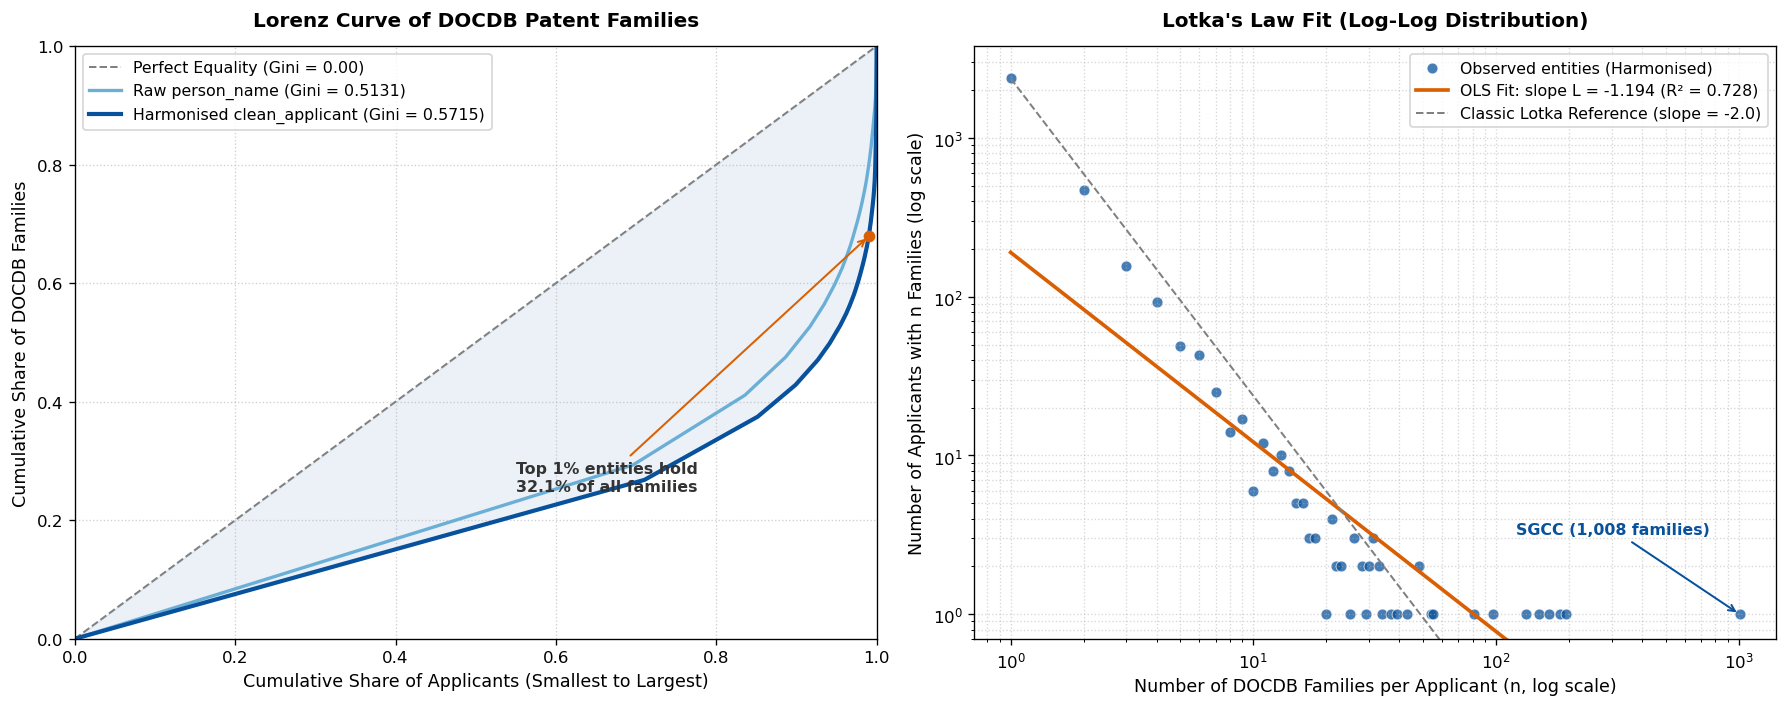

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Prepare figure with two side-by-side panels
fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=120)

# ==============================================================================
# PANEL 1: LORENZ CURVE (Pre- vs. Post-Harmonisation)
# ==============================================================================
ax1 = axes[0]

# Compute Lorenz curves using the already-defined lorenz_curve() function
f_raw, p_raw = lorenz_curve(raw_families_per_firm)
f_clean, p_clean = lorenz_curve(clean_families_per_firm)

gini_raw = gini(raw_families_per_firm)
gini_clean = gini(clean_families_per_firm)

# Line of perfect equality
ax1.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1.2, label="Perfect Equality (Gini = 0.00)")

# Lorenz curves
ax1.plot(f_raw, p_raw, color="#6baed6", linewidth=2, label=f"Raw person_name (Gini = {gini_raw:.4f})")
ax1.plot(f_clean, p_clean, color="#08519c", linewidth=2.5, label=f"Harmonised clean_applicant (Gini = {gini_clean:.4f})")
ax1.fill_between(f_clean, p_clean, f_clean, color="#08519c", alpha=0.08)

# Annotate top 1% of harmonised entities
top1_idx = int(len(f_clean) * 0.99)
top1_share = (1 - p_clean[top1_idx]) * 100
ax1.scatter([f_clean[top1_idx]], [p_clean[top1_idx]], color="#d95f02", zorder=5)
ax1.annotate(
    f"Top 1% entities hold\n{top1_share:.1f}% of all families",
    xy=(f_clean[top1_idx], p_clean[top1_idx]),
    xytext=(0.55, 0.25),
    arrowprops=dict(arrowstyle="->", color="#d95f02", lw=1.2),
    fontsize=9.5,
    fontweight="bold",
    color="#333333",
)

ax1.set_title("Lorenz Curve of DOCDB Patent Families", fontsize=12, fontweight="bold", pad=12)
ax1.set_xlabel("Cumulative Share of Applicants (Smallest to Largest)", fontsize=10.5)
ax1.set_ylabel("Cumulative Share of DOCDB Families", fontsize=10.5)
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper left", frameon=True, fontsize=9.5)

# ==============================================================================
# PANEL 2: LOTKA'S LAW (Log-Log Rank-Frequency Distribution)
# ==============================================================================
ax2 = axes[1]

freq_clean = pd.Series(clean_families_per_firm).value_counts().sort_index()
x_n = freq_clean.index.values.astype(float)      # Number of families (n)
y_f = freq_clean.values.astype(float)           # Number of entities with n families

# OLS log-log fit
slope, intercept, r_value, p_value, std_err = stats.linregress(np.log(x_n), np.log(y_f))
y_fit = np.exp(intercept + slope * np.log(x_n))

# Plot observed points and regression line
ax2.scatter(x_n, y_f, color="#08519c", alpha=0.75, s=42, edgecolor="white", linewidth=0.5, label="Observed entities (Harmonised)")
ax2.plot(
    x_n,
    y_fit,
    color="#d95f02",
    linewidth=2.2,
    label=f"OLS Fit: slope L = {slope:.3f} (R² = {r_value**2:.3f})",
)

# Reference inverse-square slope (-2.0) anchored at n=1
y_classic = y_f[0] * (x_n ** -2.0)
ax2.plot(x_n, y_classic, linestyle="--", color="gray", linewidth=1.2, label="Classic Lotka Reference (slope = -2.0)")

# Highlight SGCC outlier on the far right
max_n = int(x_n.max())
ax2.annotate(
    f"SGCC ({max_n:,} families)",
    xy=(max_n, 1),
    xytext=(max_n * 0.12, 3.2),
    arrowprops=dict(arrowstyle="->", color="#08519c", lw=1.2),
    fontsize=9.5,
    fontweight="bold",
    color="#08519c",
)

ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_title("Lotka's Law Fit (Log-Log Distribution)", fontsize=12, fontweight="bold", pad=12)
ax2.set_xlabel("Number of DOCDB Families per Applicant (n, log scale)", fontsize=10.5)
ax2.set_ylabel("Number of Applicants with n Families (log scale)", fontsize=10.5)
ax2.set_ylim(0.7, y_f.max() * 1.6)
ax2.grid(True, which="both", linestyle=":", alpha=0.5)
ax2.legend(loc="upper right", frameon=True, fontsize=9.5)

plt.tight_layout()
plt.show()

## Firms level

In [19]:
print("Columns in df_applicants:", df_applicants.columns.tolist())

if "psn_sector" in df_applicants.columns:
    print("\nBreakdown by psn_sector:")
    display(df_applicants["psn_sector"].value_counts(dropna=False))

ctry_col = next((c for c in ["person_ctry_code", "ctry", "country_code"] if c in df_applicants.columns), None)
if ctry_col:
    print(f"\nTop 15 countries by DOCDB families ({ctry_col}):")
    display(
        df_applicants.groupby(ctry_col)["docdb_family_id"]
        .nunique()
        .sort_values(ascending=False)
        .head(15)
    )

Columns in df_applicants: ['appln_id', 'person_id', 'applt_seq_nr', 'person_name', 'doc_std_name', 'psn_name', 'han_name', 'person_ctry_code', 'psn_sector', 'docdb_family_id', 'appln_auth', 'earliest_filing_year', 'clean_applicant']

Breakdown by psn_sector:


psn_sector
COMPANY                      6786
UNKNOWN                      2597
UNIVERSITY                   1447
INDIVIDUAL                    655
GOV NON-PROFIT                106
GOV NON-PROFIT UNIVERSITY      74
                               21
COMPANY GOV NON-PROFIT          5
Name: count, dtype: int64


Top 15 countries by DOCDB families (person_ctry_code):


person_ctry_code
      6530
CN     207
KR     174
JP     123
US      69
DE      66
CH      19
CA      14
GB      13
FR       8
HK       8
CZ       8
TW       7
IL       6
IT       6
Name: docdb_family_id, dtype: int64

In [20]:
import re
import numpy as np
import pandas as pd

df_work = df_applicants.copy()

# ---------------------------------------------------------------- 1. Classify 'firm' vs non-firm (recovering UNKNOWNs cleanly)
sector_clean = df_work["psn_sector"].fillna("").astype(str).str.strip().str.upper()

# Propagate known non-UNKNOWN sector within each harmonised clean_applicant
known_sector_map = (
    df_work.assign(_sec=sector_clean)
    .query("_sec != '' and _sec != 'UNKNOWN'")
    .groupby("clean_applicant")["_sec"]
    .agg(lambda s: s.mode().iloc[0])
)
resolved_sector = sector_clean.where(
    ~sector_clean.isin(["", "UNKNOWN"]),
    df_work["clean_applicant"].map(known_sector_map).fillna("UNKNOWN"),
)

# Rule-based classification for remaining UNKNOWN applicants
non_firm_kw = re.compile(
    r"\b(?:UNIVERSIT\w*|COLLEGE|SCHOOL|POLYTECHNIC|ACADEMY OF SCIENCES|MINISTRY|GOVERNMENT|MUNICIPAL|BUREAU OF)\b"
)
firm_kw = re.compile(
    r"\b(?:CO|LTD|INC|CORP|CORPORATION|LLC|GMBH|AG|SA|SPA|SRL|BV|NV|KK|PLC|GROUP|HOLDINGS|"
    r"SGCC|CSG|HUANENG|POWERCHINA|CHINA THREE GORGES|CHINA DATANG|CHINA HUADIAN|CHINA ENERGY|"
    r"POWER|ENERGY|ELECTRIC\w*|TECHNOLOG\w*|ENGINEERING|INDUSTR\w*|BATTERY|STORAGE|SYSTEMS)\b"
)

def classify_entity_type(row_name: str, sec: str) -> str:
    if "COMPANY" in sec:
        return "firm"
    if any(k in sec for k in ["UNIVERSITY", "GOV", "INDIVIDUAL"]):
        return "non_firm"
    # Fallback for UNKNOWN
    if non_firm_kw.search(row_name):
        return "non_firm"
    if firm_kw.search(row_name):
        return "firm"
    return "non_firm"

df_work["entity_type"] = [
    classify_entity_type(name, sec)
    for name, sec in zip(df_work["clean_applicant"], resolved_sector)
]

# ---------------------------------------------------------------- 2. Impute missing person_ctry_code (especially CNIPA filings)
raw_ctry = df_work["person_ctry_code"].fillna("").astype(str).str.strip().str.upper()

# Step A: propagate known person_ctry_code across the same clean_applicant
known_ctry_map = (
    df_work.assign(_ctry=raw_ctry)
    .query("_ctry != '' and _ctry != 'XX'")
    .groupby("clean_applicant")["_ctry"]
    .agg(lambda s: s.mode().iloc[0])
)
imputed_ctry = raw_ctry.where(~raw_ctry.isin(["", "XX"]), df_work["clean_applicant"].map(known_ctry_map).fillna(""))

# Step B: if still blank, fall back to filing office (appln_auth) when it is a national office
auth_clean = df_work["appln_auth"].fillna("").astype(str).str.strip().str.upper()
imputed_ctry = imputed_ctry.where(
    imputed_ctry != "",
    auth_clean.where(~auth_clean.isin(["EP", "WO", "EA", "OA", "AP"]), "UNKNOWN"),
)

df_work["clean_ctry"] = imputed_ctry

# ---------------------------------------------------------------- 3. Summary check on firms & countries
firms_df = df_work[df_work["entity_type"] == "firm"].copy()

print(f"Total rows: {len(df_work):,} | Firm rows: {len(firms_df):,} ({firms_df['clean_applicant'].nunique():,} unique firms)")
print("\nTop 15 countries among FIRMS (by DOCDB families):")
display(
    firms_df.groupby("clean_ctry")
    .agg(
        firms=("clean_applicant", "nunique"),
        families=("docdb_family_id", "nunique"),
    )
    .sort_values("families", ascending=False)
    .head(15)
)

Total rows: 11,691 | Firm rows: 9,078 (2,473 unique firms)

Top 15 countries among FIRMS (by DOCDB families):


,firms,families
clean_ctry,,
CN,2208,5021
JP,88,224
KR,49,145
DE,32,51
US,42,48
CH,6,19
GB,8,10
CA,6,9
HK,3,7


=== TABLE 1: Patents and firms by country ===


,companies,patents,mean_patents_per_firm,median_patents_per_firm,min_patents,max_patents
country,,,,,,
Canada,6.0,9.0,1.50,1.0,1.0,4.0
China,2208.0,5021.0,2.73,1.0,1.0,1008.0
Germany,32.0,51.0,1.91,1.0,1.0,15.0
Israel,6.0,6.0,1.17,1.0,1.0,2.0
Italy,3.0,5.0,2.00,1.0,1.0,4.0
Japan,88.0,224.0,2.82,1.0,1.0,37.0
Others,24.0,29.0,1.33,1.0,1.0,3.0
South Korea,49.0,145.0,3.04,1.0,1.0,30.0
Sweden,4.0,4.0,1.00,1.0,1.0,1.0



=== TABLE 2: Six concentration measures by country ===


,firms,patents (sum over firms),CV,CR4 (%),CR8 (%),HH,1/HH,Lotka L,Lotka p-value,Gini
Canada,6.0,9.000,0.816,77.778,100.000,0.259,3.857,NaN,NaN,0.278
China,2208.0,6032.000,8.326,25.696,30.355,0.032,31.412,-1.077,0.000,0.581
Germany,32.0,61.000,1.381,45.902,60.656,0.089,11.242,-1.117,0.037,0.416
Israel,6.0,7.000,0.350,71.429,100.000,0.184,5.444,NaN,NaN,0.119
Italy,3.0,6.000,0.866,100.000,100.000,0.500,2.000,NaN,NaN,0.333
Japan,88.0,248.000,1.549,26.613,39.113,0.038,26.105,-1.145,0.000,0.503
South Korea,49.0,149.000,1.933,57.047,69.799,0.095,10.517,-0.722,0.045,0.601
Sweden,4.0,4.000,0.000,100.000,100.000,0.250,4.000,NaN,NaN,0.000
Switzerland,6.0,19.000,0.506,84.211,100.000,0.202,4.945,0.504,0.144,0.254
Taiwan,2.0,4.000,0.707,100.000,100.000,0.625,1.600,NaN,NaN,0.250



=== TABLE 3: Country concentration rankings (1 = most concentrated) ===


,CV,CR4 (%),CR8 (%),HH,Lotka L,Gini
rank,,,,,,
1,China,Sweden,Canada,Taiwan,Switzerland,South Korea
2,South Korea,Italy,Israel,Italy,South Korea,China
3,Japan,Taiwan,Sweden,Canada,China,Japan
4,Germany,Switzerland,Italy,Sweden,Germany,Germany
5,United States,Canada,Taiwan,Switzerland,Japan,Italy
6,Italy,Israel,United Kingdom,Israel,United Kingdom,Canada
7,Canada,United Kingdom,Switzerland,United Kingdom,United States,Switzerland
8,Taiwan,South Korea,South Korea,South Korea,Canada,Taiwan
9,United Kingdom,Germany,Germany,Germany,Israel,United States



=== TABLE 4: Kendall's tau-b rank correlation across measures ===


,CV,CR4 (%),CR8 (%),HH,Lotka L,Gini
CV,1.000**,-0.543**,-0.642**,-0.455**,0.143,0.788**
CR4 (%),-0.543**,1.000**,0.808**,0.915**,0.238,-0.388*
CR8 (%),-0.642**,0.808**,1.000**,0.789**,0.293,-0.459*
HH,-0.455**,0.915**,0.789**,1.000**,0.238,-0.303
Lotka L,0.143,0.238,0.293,0.238,1.000**,0.429
Gini,0.788**,-0.388*,-0.459*,-0.303,0.429,1.000**


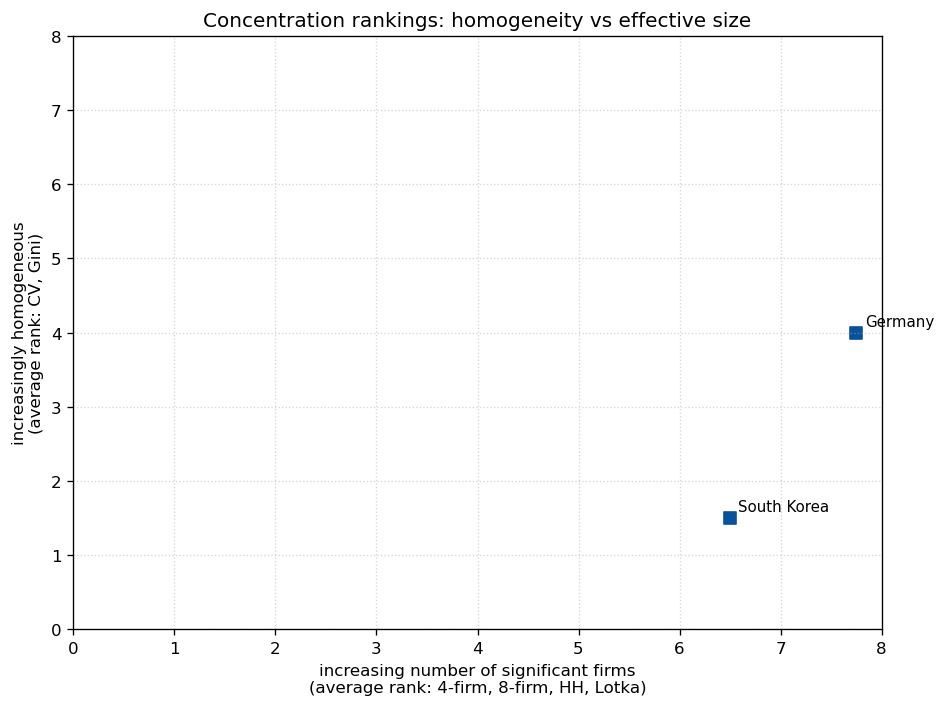

In [21]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from scipy import stats

# ---------------------------------------------------------------- 1. Define top 12 countries & prepare firm-country table
COUNTRY_NAMES = {
    "CN": "China",
    "JP": "Japan",
    "KR": "South Korea",
    "DE": "Germany",
    "US": "United States",
    "CH": "Switzerland",
    "GB": "United Kingdom",
    "CA": "Canada",
    "IL": "Israel",
    "IT": "Italy",
    "TW": "Taiwan",
    "SE": "Sweden",
}

firms_sec4 = firms_df.copy()
firms_sec4["country"] = firms_sec4["clean_ctry"].map(COUNTRY_NAMES).fillna("Others")

# One row per firm & country (counting distinct DOCDB families)
firm_patents = (
    firms_sec4.groupby(["clean_applicant", "clean_ctry", "country"])["docdb_family_id"]
    .nunique()
    .rename("patents")
    .reset_index()
)

# ---------------------------------------------------------------- 2. Table 1: Patents and firms by country
table1 = firm_patents.groupby("country").agg(
    companies=("clean_applicant", "count"),
    mean_patents_per_firm=("patents", "mean"),
    median_patents_per_firm=("patents", "median"),
    min_patents=("patents", "min"),
    max_patents=("patents", "max"),
)

# Distinct families per country (each co-owned patent within the same country counts once)
patents_by_country = firms_sec4.groupby("country")["docdb_family_id"].nunique()
table1.insert(1, "patents", patents_by_country)
table1.loc["Total", ["companies", "patents"]] = [
    len(firm_patents),
    firms_sec4["docdb_family_id"].nunique(),
]

print("=== TABLE 1: Patents and firms by country ===")
display(table1.round(2))

# ---------------------------------------------------------------- 3. Table 2: Six concentration measures across the 12 countries
table2 = pd.DataFrame({
    country: six_measures(group["patents"].to_numpy())
    for country, group in firm_patents.groupby("country")
    if country != "Others"
}).T
table2.loc["Average"] = table2.mean()

print("\n=== TABLE 2: Six concentration measures by country ===")
display(table2.round(3))

# ---------------------------------------------------------------- 4. Table 3: Country rankings under each measure (1 = most concentrated)
MEASURES = ["CV", "CR4 (%)", "CR8 (%)", "HH", "Lotka L", "Gini"]

scores = table2.drop(index="Average")[MEASURES].copy()
scores["Lotka L"] = -scores["Lotka L"].abs()  # Less negative slope (closer to 0) = higher concentration

ranks = scores.rank(ascending=False, method="min")
table3 = pd.DataFrame({m: ranks.sort_values(m).index for m in MEASURES})
table3.index = range(1, len(table3) + 1)
table3.index.name = "rank"

print("\n=== TABLE 3: Country concentration rankings (1 = most concentrated) ===")
display(table3)

# ---------------------------------------------------------------- 5. Table 4: Kendall's tau-b concordance across measures
table4 = pd.DataFrame(index=MEASURES, columns=MEASURES, dtype=object)
for a in MEASURES:
    for b in MEASURES:
        tau, p_value = stats.kendalltau(scores[a], scores[b], nan_policy="omit")
        if pd.isna(tau):
            table4.loc[a, b] = "NaN"
        else:
            star = "**" if p_value < 0.05 else "*" if p_value < 0.10 else ""
            table4.loc[a, b] = f"{tau:.3f}{star}"

print("\n=== TABLE 4: Kendall's tau-b rank correlation across measures ===")
display(table4)

# ---------------------------------------------------------------- 6. Figure (4.9): Two dimensions of concentration
valid_countries = ranks.dropna().index
x = ranks.loc[valid_countries, ["CR4 (%)", "CR8 (%)", "HH", "Lotka L"]].mean(axis=1)
y = ranks.loc[valid_countries, ["CV", "Gini"]].mean(axis=1)

fig, ax = plt.subplots(figsize=(8, 6), dpi=120)
ax.scatter(x, y, marker="s", color="#08519c", s=45)
for country in valid_countries:
    ax.annotate(country, (x[country], y[country]), xytext=(5, 4), textcoords="offset points", fontsize=9)

n_c = len(valid_countries)
ax.set(
    xlim=(0, n_c + 1),
    ylim=(0, n_c + 1),
    title="Concentration rankings: homogeneity vs effective size",
    xlabel="increasing number of significant firms\n(average rank: 4-firm, 8-firm, HH, Lotka)",
    ylabel="increasingly homogeneous\n(average rank: CV, Gini)",
)
ax.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

# Step 2 

## Sectors

In [22]:
# 1. Sector families and filing/priority year from the already-filtered applicants dataset
families_df = (
    df_applicants.groupby("docdb_family_id", as_index=False)["earliest_filing_year"]
    .min()
    .rename(columns={"docdb_family_id": "unit_id", "earliest_filing_year": "year"})
)
families_df = families_df[families_df["year"].between(YEAR_MIN, YEAR_MAX)].copy()

# 2. Harmonised applicants per family (one row per family and clean_applicant)
raw_sector = (
    df_applicants.merge(families_df, left_on="docdb_family_id", right_on="unit_id", how="inner")
    [["unit_id", "year", "clean_applicant"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

# 3. CPC codes per family queried from PATSTAT restricted to sector families
sector_unit_ids = families_df["unit_id"].unique().tolist()
q_cpc = (
    db.query(
        TLS201_APPLN.docdb_family_id.label("unit_id"),
        func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "").label("cpc"),
    )
    .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
    .filter(TLS201_APPLN.docdb_family_id.in_(sector_unit_ids))
    .distinct()
)
family_cpc = (
    patstat.df(q_cpc)
    .merge(families_df[["unit_id", "year"]], on="unit_id", how="inner")
    [["unit_id", "year", "cpc"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print(f"{raw_sector['unit_id'].nunique():,} families")

6,605 families


In [23]:
print("Total unique families in df_applicants:", df_applicants["docdb_family_id"].nunique())
print("Null years in df_applicants:", df_applicants["earliest_filing_year"].isna().sum())
print("Min/Max year in df_applicants:", df_applicants["earliest_filing_year"].min(), df_applicants["earliest_filing_year"].max())
print("Families kept after YEAR_MIN..YEAR_MAX:", len(families_df))

Total unique families in df_applicants: 6838
Null years in df_applicants: 0
Min/Max year in df_applicants: 2001 2026
Families kept after YEAR_MIN..YEAR_MAX: 6605


In [24]:
# 4. First patent ever (in any field) per harmonised applicant + metadata for Section 5.2
# Filter df_applicants to the sector families kept in families_df
sector_appl = (
    df_applicants.merge(
        families_df[["unit_id", "year"]],
        left_on="docdb_family_id",
        right_on="unit_id",
        how="inner",
    )
    .drop_duplicates()
    .reset_index(drop=True)
)

appl_ids = [int(i) for i in sector_appl["appln_id"].dropna().unique()]
person_meta_chunks = []

# Query PATSTAT in chunks to retrieve psn_id, country (ctry), and sector type (psn_sector)
for start in range(0, len(appl_ids), 5000):
    q_meta = (
        db.query(
            TLS207_PERS_APPLN.appln_id,
            TLS206_PERSON.person_name,
            TLS206_PERSON.psn_id,
            func.trim(TLS206_PERSON.person_ctry_code).label("ctry"),
            TLS206_PERSON.psn_sector,
        )
        .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
        .filter(
            TLS207_PERS_APPLN.appln_id.in_(appl_ids[start : start + 5000]),
            TLS207_PERS_APPLN.applt_seq_nr > 0,
        )
        .distinct()
    )
    person_meta_chunks.append(patstat.df(q_meta))

person_meta = (
    pd.concat(person_meta_chunks, ignore_index=True)
    if person_meta_chunks
    else pd.DataFrame(columns=["appln_id", "person_name", "psn_id", "ctry", "psn_sector"])
)

# Map each harmonised applicant to its underlying psn_id values via appln_id (and person_name fallback)
appl_map = sector_appl[["appln_id", "clean_applicant", "person_name"]].drop_duplicates()
psn_map = (
    appl_map.merge(person_meta[["appln_id", "psn_id"]], on="appln_id", how="inner")
    [["clean_applicant", "psn_id"]]
    .dropna(subset=["psn_id"])
    .drop_duplicates()
)

psn_ids = [int(i) for i in psn_map["psn_id"].unique()]
first_patents = []

# Query PATSTAT in chunks to find the earliest filing year ever (across all fields) per psn_id
for start in range(0, len(psn_ids), 5000):
    q_first = (
        db.query(
            TLS206_PERSON.psn_id,
            func.min(TLS201_APPLN.earliest_filing_year).label("first_patent_year"),
        )
        .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
        .join(TLS201_APPLN, TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)
        .filter(
            TLS206_PERSON.psn_id.in_(psn_ids[start : start + 5000]),
            TLS207_PERS_APPLN.applt_seq_nr > 0,
            TLS201_APPLN.earliest_filing_year.between(1900, YEAR_MAX),
        )
        .group_by(TLS206_PERSON.psn_id)
    )
    first_patents.append(patstat.df(q_first))

first_patents = (
    pd.concat(first_patents, ignore_index=True)
    if first_patents
    else pd.DataFrame(columns=["psn_id", "first_patent_year"])
)

# Earliest patent filing year ever per harmonised applicant
first_ever = (
    psn_map.merge(first_patents, on="psn_id", how="inner")
    .groupby("clean_applicant")["first_patent_year"]
    .min()
)

# Attach country and sector type to family-applicant links
meta_by_appl = person_meta[["appln_id", "psn_id", "ctry", "psn_sector"]].drop_duplicates()
links = (
    sector_appl[["unit_id", "year", "appln_id", "clean_applicant"]]
    .merge(meta_by_appl, on="appln_id", how="left")
    .rename(columns={"clean_applicant": "applicant"})
    [["unit_id", "year", "applicant", "ctry", "psn_sector"]]
    .drop_duplicates(subset=["unit_id", "year", "applicant", "ctry", "psn_sector"])
    .reset_index(drop=True)
)

print(f"{links['applicant'].nunique():,} applicants on {links['unit_id'].nunique():,} families")

3,256 applicants on 6,605 families


## 5.1 how concentrated is the field?

In [25]:
complete = links[links["year"] <= LAST_COMPLETE_YEAR]
families_per_applicant = complete.groupby("applicant")["unit_id"].nunique()

pd.Series(six_measures(families_per_applicant.to_numpy()), name=SECTOR_NAME).round(3).to_frame()

,Utility-Scale Energy Storage
firms,1914.000
patents (sum over firms),4299.000
CV,5.279
CR4 (%),15.911
CR8 (%),19.749
HH,0.015
1/HH,66.340
Lotka L,-1.327
Lotka p-value,0.000
Gini,0.502


In [26]:
# Check unique families retained after filtering by LAST_COMPLETE_YEAR
print("Unique families in links:", links["unit_id"].nunique())
print("Unique families in complete:", complete["unit_id"].nunique())
print("Applicants dropped after LAST_COMPLETE_YEAR:", links["applicant"].nunique() - complete["applicant"].nunique())

Unique families in links: 6605
Unique families in complete: 3279
Applicants dropped after LAST_COMPLETE_YEAR: 1342


,year,firms,total_families,HH,CR4 (%)
0,2001,4.0,1.0,0.250,100.000
1,2003,9.0,2.0,0.111,44.444
2,2004,1.0,1.0,1.000,100.000
3,2005,7.0,7.0,0.143,57.143
4,2006,16.0,4.0,0.062,25.000
5,2007,30.0,18.0,0.038,23.529
6,2008,20.0,7.0,0.050,20.000
7,2009,68.0,19.0,0.018,15.000
8,2010,68.0,36.0,0.017,12.821
9,2011,120.0,63.0,0.010,10.000


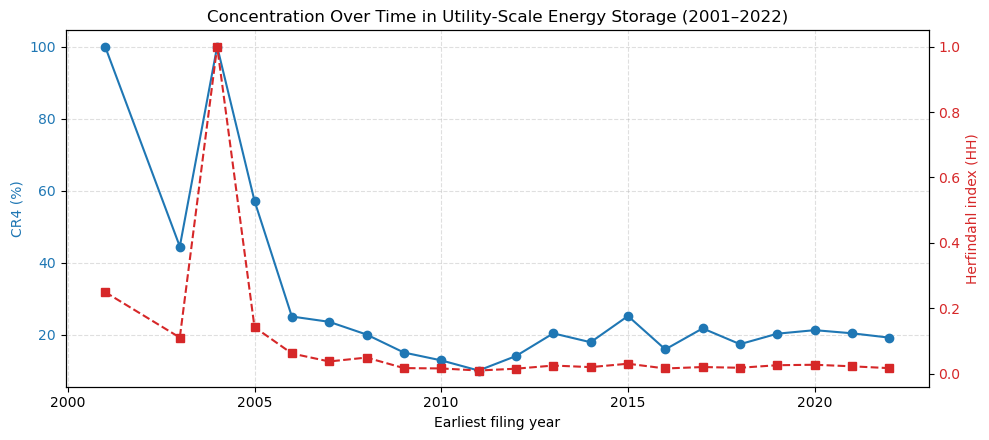

In [27]:
# Compute annual patent families per harmonised applicant in the completed period
annual_counts = (
    complete.groupby(["year", "applicant"])["unit_id"]
    .nunique()
    .reset_index(name="families")
)

# Calculate Herfindahl index (HH) and 4-firm concentration ratio (CR4) per year
conc_over_time = (
    annual_counts.groupby("year")["families"]
    .apply(
        lambda s: pd.Series(
            {
                "firms": len(s),
                "total_families": complete[complete["year"] == s.name]["unit_id"].nunique(),
                "HH": herfindahl(s.to_numpy()),
                "CR4 (%)": concentration_ratio(s.to_numpy(), 4),
            }
        )
    )
    .unstack()
    .reset_index()
)

display(conc_over_time.round(3))

# Plot HH and CR4 over time (dual axis)
fig, ax1 = plt.subplots(figsize=(10, 4.5))

color_cr4 = "#1f77b4"
ax1.plot(conc_over_time["year"], conc_over_time["CR4 (%)"], marker="o", color=color_cr4, label="CR4 (%)")
ax1.set_xlabel("Earliest filing year")
ax1.set_ylabel("CR4 (%)", color=color_cr4)
ax1.tick_params(axis="y", labelcolor=color_cr4)
ax1.grid(True, linestyle="--", alpha=0.4)

ax2 = ax1.twinx()
color_hh = "#d62728"
ax2.plot(conc_over_time["year"], conc_over_time["HH"], marker="s", linestyle="--", color=color_hh, label="Herfindahl (HH)")
ax2.set_ylabel("Herfindahl index (HH)", color=color_hh)
ax2.tick_params(axis="y", labelcolor=color_hh)

plt.title(f"Concentration Over Time in {SECTOR_NAME} ({YEAR_MIN}–{LAST_COMPLETE_YEAR})")
fig.tight_layout()
plt.show()

* **Moderate-to-high top concentration with low aggregate HH:** Over the consolidated period (`2001–2022`, i.e., `year <= LAST_COMPLETE_YEAR`, covering **1,914** harmonised applicants and **4,299** applicant-family assignments across **3,279** unique families), the top four entities account for a **CR4 of 15.911%** and the top eight for a **CR8 of 19.749%**, while the aggregate Herfindahl index remains low at **HH = 0.015** (**1/HH = 66.340** effective equal-sized competitors).
* **Skewed, heavy-tailed distribution:** High dispersion and inequality across applicants are confirmed by **CV = 5.279**, **Gini = 0.502**, and a Lotka exponent of **L = -1.327** (`p-value = 0.000`), reflecting a long tail of occasional patentees alongside major incumbents.
* **No evidence of consolidation over time:** After initial small-sample volatility in `2001–2005` (`1–7` families/year), concentration fell sharply as new entrants joined the field, reaching a trough in `2011` (`CR4 = 10.000%`, `HH = 0.010`). Between `2012` and `2022`, despite annual patenting expanding nearly tenfold (`78` to `750` families/year and `91` to `511` active applicants/year), **HH** remained stable at low levels (`0.016–0.031`, `0.018` in `2022`) and **CR4** stayed contained within `14%–25%` (`19.131%` in `2022`), indicating sustained entry rather than market consolidation.

,All applicants,Companies only
firms,1914.000,1267.000
patents (sum over firms),4299.000,2986.000
CV,5.279,5.550
CR4 (%),15.911,20.094
CR8 (%),19.749,24.447
HH,0.015,0.025
1/HH,66.340,39.874
Lotka L,-1.327,-1.296
Lotka p-value,0.000,0.000
Gini,0.502,0.514


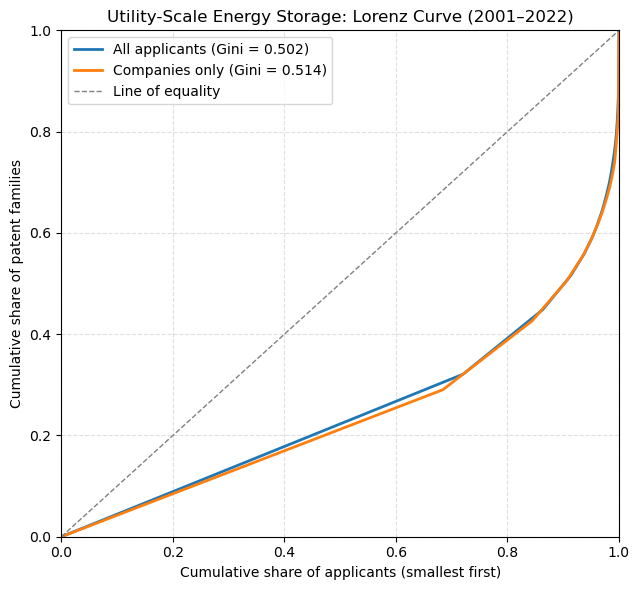

In [28]:
# Robustness check in Section 5.1: All harmonised applicants vs. Companies only + Lorenz curve
comp_all = complete.groupby("applicant")["unit_id"].nunique()
comp_firms = (
    complete[complete["psn_sector"] == "COMPANY"]
    .groupby("applicant")["unit_id"]
    .nunique()
)

comparison_5_1 = pd.DataFrame(
    {
        "All applicants": six_measures(comp_all.to_numpy()),
        "Companies only": six_measures(comp_firms.to_numpy()),
    }
).round(3)
display(comparison_5_1)

# Plot Lorenz curve comparing all applicants vs. companies only
fig, ax = plt.subplots(figsize=(6.5, 6))
for label, series in [("All applicants", comp_all), ("Companies only", comp_firms)]:
    x_firms, y_patents = lorenz_curve(series.to_numpy())
    ax.plot(x_firms, y_patents, lw=2, label=f"{label} (Gini = {gini(series.to_numpy()):.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="grey", lw=1, label="Line of equality")
ax.set(
    title=f"{SECTOR_NAME}: Lorenz Curve ({YEAR_MIN}–{LAST_COMPLETE_YEAR})",
    xlabel="Cumulative share of applicants (smallest first)",
    ylabel="Cumulative share of patent families",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend(loc="upper left")
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### Institutional Composition and Concentration Note (Section 5.1)

* **Industry-driven landscape with a strong academic pillar:** Over the consolidated period (`2001–2022`), private companies (`COMPANY`) account for **1,267 of the 1,914** active harmonised applicants (**66.2%**) and **2,986 of the 4,299** applicant-family assignments (**69.5%**). Utility-Scale Energy Storage is therefore primarily an industry-led field driven by large electric utilities, grid-equipment manufacturers, and energy conglomerates (such as *SGCC*, *CSG*, *Huaneng*, and *PowerChina*).
* **Why corporate concentration is higher than aggregate concentration:** The remaining **647 non-corporate entities** (**33.8%**) consist largely of universities and public research institutes (e.g., *North China Electric Power University*, *Tsinghua University*, and *Chinese Academy of Sciences*) that patent actively in grid integration and storage systems. Removing non-corporate actors from the denominator increases top-firm concentration (**CR4** rises from **15.911%** to **20.094%**, **CR8** from **19.749%** to **24.447%**, and **HH** from **0.015** to **0.025**, reducing effective competitors **1/HH** from **66.340** to **39.874**), highlighting the stronger market weight of leading industrial incumbents relative to smaller corporate entrants.
* **Consistent structural inequality:** Despite higher top-firm shares among companies, the overall shape of the distribution remains virtually unchanged (**Gini = 0.502** overall vs. **0.514** for companies; **Lotka L = -1.327** vs. **-1.296**), confirming a heavy-tailed structure across both the full ecosystem and the corporate segment alone.

## 5.2 Who are the incumbents, and who are the new entrants? Top applicants with type and country; new applicants per year, their share of families, and the rate of disappearance

,type,country,families,families since 2015,first year in the sector,last year in the sector,first patent ever,status
SGCC,COMPANY,CN,970,927,2010,2025,1980,incumbent
CSG (CHINA SOUTHERN POWER GRID),COMPANY,CN,188,186,2011,2025,1985,incumbent
HUANENG,COMPANY,CN,173,173,2017,2025,1985,entrant
XIAN THERMAL POWER RESEARCH INSTITUTE,COMPANY,CN,157,157,2019,2025,1985,entrant
NORTH CHINA ELECTRIC POWER UNIVERSITY,UNIVERSITY,CN,150,141,2011,2025,1985,incumbent
TSINGHUA UNIVERSITY,UNIVERSITY,CN,126,119,2007,2025,1985,incumbent
POWERCHINA,COMPANY,CN,92,92,2017,2025,1985,entrant
CHINA THREE GORGES,COMPANY,CN,75,75,2015,2025,1985,entrant
SUNGROW POWER SUPPLY,COMPANY,CN,55,55,2018,2025,1985,entrant
CHINESE ACADEMY OF SCIENCES,GOV NON-PROFIT UNIVERSITY,CN,53,49,2007,2025,1985,incumbent


,type,country,families,families since 2015,first year in the sector,last year in the sector,first patent ever,status
SGCC,COMPANY,CN,970,927,2010,2025,1980,incumbent
CSG (CHINA SOUTHERN POWER GRID),COMPANY,CN,188,186,2011,2025,1985,incumbent
HUANENG,COMPANY,CN,173,173,2017,2025,1985,entrant
XIAN THERMAL POWER RESEARCH INSTITUTE,COMPANY,CN,157,157,2019,2025,1985,entrant
NORTH CHINA ELECTRIC POWER UNIVERSITY,UNIVERSITY,CN,150,141,2011,2025,1985,incumbent
TSINGHUA UNIVERSITY,UNIVERSITY,CN,126,119,2007,2025,1985,incumbent
POWERCHINA,COMPANY,CN,92,92,2017,2025,1985,entrant
CHINA THREE GORGES,COMPANY,CN,75,75,2015,2025,1985,entrant
SUNGROW POWER SUPPLY,COMPANY,CN,55,55,2018,2025,1985,entrant
CHINESE ACADEMY OF SCIENCES,GOV NON-PROFIT UNIVERSITY,CN,53,49,2007,2025,1985,incumbent


,active_applicants,new_to_the_sector,new_to_patenting,leaving,rate of disappearance (%),entrants' share of families (%)
year,,,,,,
2001,4,4,0,4,100.0,100.0
2003,9,9,0,8,88.9,100.0
2004,1,0,0,0,0.0,0.0
2005,7,7,0,4,57.1,100.0
2006,16,16,1,13,81.2,100.0
2007,30,30,0,18,60.0,100.0
2008,20,17,0,17,85.0,85.7
2009,68,65,2,60,88.2,94.7
2010,68,62,1,50,73.5,94.4


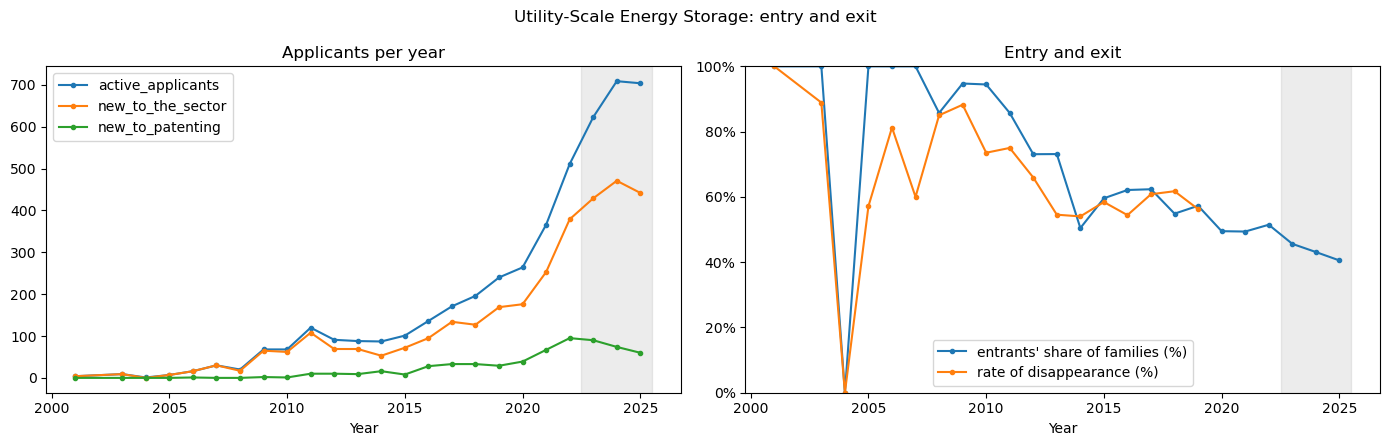

Among the 15 largest applicants, 7 are incumbents and 8 are entrants.
Largest incumbents: SGCC, CSG (CHINA SOUTHERN POWER GRID), NORTH CHINA ELECTRIC POWER UNIVERSITY.
Largest entrants (first family from 2015): HUANENG, XIAN THERMAL POWER RESEARCH INSTITUTE, POWERCHINA.
In the last five complete years, on average 52% of each year's families had at least one applicant new to the sector.


In [29]:
from matplotlib.ticker import PercentFormatter

# Helper to pick the most frequent non-null metadata value (type/country) per harmonised applicant
def _mode_or_first(s):
    s_clean = s.dropna()
    if s_clean.empty:
        return np.nan
    modes = s_clean.mode()
    return modes.iloc[0] if not modes.empty else s_clean.iloc[0]

# Fix blank country codes in links by treating empty strings as missing and falling back to filing authority
links["ctry"] = links["ctry"].replace(r"^\s*$", np.nan, regex=True)
links["psn_sector"] = links["psn_sector"].replace(r"^\s*$", np.nan, regex=True)

# Optional fallback from TLS201_APPLN.appln_auth for applicants with no non-empty person_ctry_code
missing_ctry_appl = (
    sector_appl.merge(links[links["ctry"].isna()][["unit_id", "applicant"]].drop_duplicates(), on="unit_id")
    [["applicant", "appln_id"]]
    .drop_duplicates()
)
if not missing_ctry_appl.empty:
    m_ids = [int(i) for i in missing_ctry_appl["appln_id"].dropna().unique()]
    auth_chunks = []
    for start in range(0, len(m_ids), 5000):
        q_auth = db.query(TLS201_APPLN.appln_id, func.trim(TLS201_APPLN.appln_auth).label("auth")).filter(
            TLS201_APPLN.appln_id.in_(m_ids[start : start + 5000])
        )
        auth_chunks.append(patstat.df(q_auth))
    auth_df = pd.concat(auth_chunks, ignore_index=True)
    fallback_ctry = (
        missing_ctry_appl.merge(auth_df, on="appln_id", how="inner")
        .groupby("applicant")["auth"]
        .agg(_mode_or_first)
    )
    links["ctry"] = links["ctry"].fillna(links["applicant"].map(fallback_ctry))

# 1. Top applicants with type, country, activity span, and incumbent/entrant status
by_applicant = links.groupby("applicant")
top_applicants = (
    pd.DataFrame(
        {
            "type": by_applicant["psn_sector"].agg(_mode_or_first),
            "country": by_applicant["ctry"].agg(_mode_or_first),
            "families": by_applicant["unit_id"].nunique(),
            f"families since {SPLIT_YEAR}": links[links["year"] >= SPLIT_YEAR]
            .groupby("applicant")["unit_id"]
            .nunique(),
            "first year in the sector": by_applicant["year"].min(),
            "last year in the sector": by_applicant["year"].max(),
            "first patent ever": first_ever,
        }
    )
    .dropna(subset=["families"])
    .fillna({f"families since {SPLIT_YEAR}": 0})
)

top_applicants["families"] = top_applicants["families"].astype(int)
top_applicants[f"families since {SPLIT_YEAR}"] = top_applicants[f"families since {SPLIT_YEAR}"].astype(int)
top_applicants["status"] = np.where(
    top_applicants["first year in the sector"] < SPLIT_YEAR, "incumbent", "entrant"
)
top_applicants = top_applicants.sort_values("families", ascending=False)

type_overrides = {
    "HUAWEI": "COMPANY",
    "HITHIUM (XIAMEN HAICHEN)": "COMPANY",
}
top_applicants["type"] = top_applicants.index.to_series().map(type_overrides).fillna(top_applicants["type"])
display(top_applicants.head(TOP_N))
display(top_applicants.head(TOP_N))

# 2. Entry and exit year by year
first_year = by_applicant["year"].min()      # first family of each applicant in the sector
last_year = by_applicant["year"].max()       # last family of each applicant in the sector

active = links[["applicant", "year"]].drop_duplicates()
active["new to the sector"] = active["year"] == active["applicant"].map(first_year)
active["new to patenting"] = active["year"] == active["applicant"].map(first_ever)
active["last family"] = active["year"] == active["applicant"].map(last_year)

entry_exit = active.groupby("year").agg(
    active_applicants=("applicant", "count"),
    new_to_the_sector=("new to the sector", "sum"),
    new_to_patenting=("new to patenting", "sum"),
    leaving=("last family", "sum"),
)
entry_exit["rate of disappearance (%)"] = entry_exit["leaving"] / entry_exit["active_applicants"] * 100
entry_exit.loc[entry_exit.index > LAST_COMPLETE_YEAR - 3, "rate of disappearance (%)"] = np.nan

# Share of each year's families with at least one applicant new to the sector
links_new = links.assign(new=links["year"] == links["applicant"].map(first_year))
entry_exit["entrants' share of families (%)"] = (
    links_new.groupby(["year", "unit_id"])["new"].any().groupby("year").mean() * 100
)
display(entry_exit.round(1))

# 3. Plot entry and exit dynamics
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
entry_exit[["active_applicants", "new_to_the_sector", "new_to_patenting"]].plot(ax=axes[0], marker="o", ms=3)
axes[0].set(title="Applicants per year", xlabel="Year")
entry_exit[["entrants' share of families (%)", "rate of disappearance (%)"]].plot(ax=axes[1], marker="o", ms=3)
axes[1].set(title="Entry and exit", xlabel="Year", ylim=(0, 100))
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
for ax in axes:
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.15)   # incomplete years
fig.suptitle(f"{SECTOR_NAME}: entry and exit")
plt.tight_layout()
plt.show()

# 4. Summary answer
top = top_applicants.head(TOP_N)
incumbents = top[top["status"] == "incumbent"].index.tolist()
entrants = top[top["status"] == "entrant"].index.tolist()
recent_entry = entry_exit.loc[LAST_COMPLETE_YEAR - 4 : LAST_COMPLETE_YEAR, "entrants' share of families (%)"].mean()

print(
    f"Among the {TOP_N} largest applicants, {len(incumbents)} are incumbents and {len(entrants)} are entrants.\n"
    f"Largest incumbents: {', '.join(incumbents[:3]) or 'none'}.\n"
    f"Largest entrants (first family from {SPLIT_YEAR}): {', '.join(entrants[:3]) or 'none'}.\n"
    f"In the last five complete years, on average {recent_entry:.0f}% of each year's families had at least one applicant new to the sector."
)

### 5.2 Incumbents and New Entrants in Utility-Scale Energy Storage

* **Top 15 balance between incumbents and entrants (`SPLIT_YEAR = 2015`):** Among the 15 largest harmonised applicants, **7 are incumbents** (active in the sector before 2015) and **8 are entrants** (first sector family from 2015 onward).
* **Leading incumbents and entrants:** The largest incumbents are **SGCC** (970 families, first in sector 2010), **CSG (CHINA SOUTHERN POWER GRID)** (188 families, 2011), and **NORTH CHINA ELECTRIC POWER UNIVERSITY** (150 families, 2011), alongside **TSINGHUA UNIVERSITY** (126 families, 2007), **CHINESE ACADEMY OF SCIENCES** (53 families, 2007), **SHANGHAI JIAO TONG UNIVERSITY** (39 families, 2012), and **KOBE STEEL** (37 families, 2014). The largest entrants are **HUANENG** (173 families, 2017), **XIAN THERMAL POWER RESEARCH INSTITUTE** (157 families, 2019), and **POWERCHINA** (92 families, 2017), followed by **CHINA THREE GORGES** (75, 2015), **SUNGROW POWER SUPPLY** (55, 2018), **HUAWEI** (48, 2018), **HITHIUM (XIAMEN HAICHEN)** (47, 2021), and **XIAN JIAOTONG UNIVERSITY** (41, 2016).
* **Geographic and institutional profile:** Fourteen of the top 15 applicants are based in **China (`CN`)** and one in **Japan (`JP`, Kobe Steel)**. The top group combines utilities, power equipment/battery firms, and tech companies with strong academic and public research institutions (`UNIVERSITY` and `GOV NON-PROFIT UNIVERSITY`).
* **Diversification by experienced patentees:** Nearly all top entrants had prior patenting histories decades earlier (`first patent ever` between 1985 and 1995), showing that major sector expansion has been driven largely by established industrial and utility players diversifying into utility-scale energy storage rather than first-time patentees.
* **Sustained entry and high turnover:** Active applicants grow steadily from 4 in 2001 to 511 in 2022 (reaching 704–709 in 2024–2025). In the last five complete years (`2018–2022`), on average **52%** of each year's families involved at least one applicant new to the sector, while the disappearance rate among earlier consolidated cohorts (`2012–2019`) typically ranged between **54.0%** and **65.9%**, reflecting frequent sporadic or project-based filing alongside persistent core players.

## 5.3 Which subfields are growing fastest?	Growth of the CPC groups of the sector between two periods (Section 5.3)

,families 2013-2017,families 2018-2022,growth (%)
subfield,,,
H02J3/32,273,1218,346.2
Y02E70/30,293,625,113.3
H02J3/38,143,539,276.9
H02J3/00,50,481,862.0
Y02E60/16,162,414,155.6
...,...,...,...
B60L58/19,1,0,-100.0
B60L58/25,1,0,-100.0
B60L58/26,2,0,-100.0


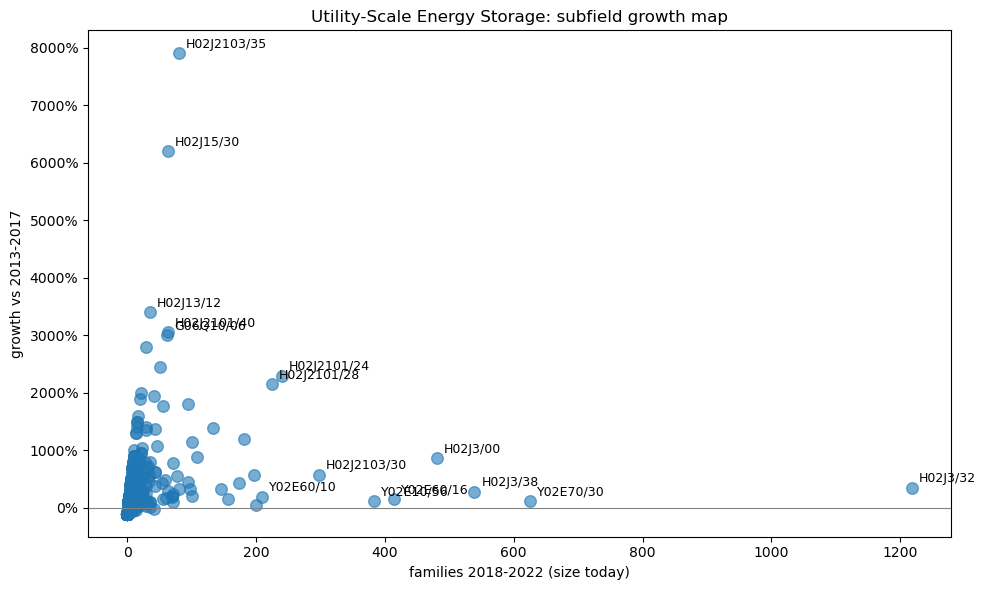

Fastest-growing subfields (>= median size in 2018-2022): H02J2103/35 (+7900%), H02J15/30 (+6200%), H02J13/12 (+3400%)


In [32]:
# 5.3 Subfield growth comparison across two 5-year windows
RECENT = (LAST_COMPLETE_YEAR - 4, LAST_COMPLETE_YEAR)   # last 5 complete years (e.g., 2018–2022)
PAST = (RECENT[0] - 5, RECENT[0] - 1)                   # preceding 5 years (e.g., 2013–2017)


def subfield(cpc):
    "CPC group with the first two digits after the slash: H01M8/1004 -> H01M8/10."
    cpc_clean = str(cpc).strip().replace(" ", "")
    if "/" not in cpc_clean:
        return cpc_clean
    main_group, subgroup = cpc_clean.split("/", 1)
    return f"{main_group}/{subgroup[:2]}"


# Ensure family_cpc has 'year' (fallback to families_df or links if needed)
cpc_df = family_cpc.copy()
if "year" not in cpc_df.columns:
    year_ref = (
        families_df[["unit_id", "year"]].drop_duplicates("unit_id")
        if "families_df" in globals()
        else links[["unit_id", "year"]].drop_duplicates("unit_id")
    )
    cpc_df = cpc_df.merge(year_ref, on="unit_id", how="inner")

# Filter to sector CPC prefixes if defined, otherwise keep all families in the sector perimeter
if "SECTOR_CPC_PREFIXES" in globals() and SECTOR_CPC_PREFIXES:
    prefixes = tuple(p.replace(" ", "") for p in SECTOR_CPC_PREFIXES)
    cpc_clean_series = cpc_df["cpc"].astype(str).str.replace(" ", "", regex=False)
    in_sector = cpc_df[cpc_clean_series.str.startswith(prefixes)].copy()
else:
    valid_units = set(links["unit_id"].unique())
    in_sector = cpc_df[cpc_df["unit_id"].isin(valid_units)].copy()

in_sector["subfield"] = in_sector["cpc"].map(subfield)
in_sector = in_sector.drop_duplicates(["unit_id", "subfield"])

past = in_sector[in_sector["year"].between(*PAST)].groupby("subfield")["unit_id"].nunique()
recent = in_sector[in_sector["year"].between(*RECENT)].groupby("subfield")["unit_id"].nunique()

subfields = pd.DataFrame(
    {
        f"families {PAST[0]}-{PAST[1]}": past,
        f"families {RECENT[0]}-{RECENT[1]}": recent,
    }
).fillna(0)
subfields[f"families {PAST[0]}-{PAST[1]}"] = subfields[f"families {PAST[0]}-{PAST[1]}"].astype(int)
subfields[f"families {RECENT[0]}-{RECENT[1]}"] = subfields[f"families {RECENT[0]}-{RECENT[1]}"].astype(int)
subfields["growth (%)"] = np.where(
    subfields.iloc[:, 0] > 0,
    (subfields.iloc[:, 1] / subfields.iloc[:, 0] - 1) * 100,
    np.nan,
)
subfields = subfields.sort_values(subfields.columns[1], ascending=False)
display(subfields.round(1))

# Scatter map for subfields that already existed in the PAST window
plot = subfields[subfields.iloc[:, 0] > 0].copy()
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(plot.iloc[:, 1], plot["growth (%)"], s=70, alpha=0.6)

to_label = set(plot.head(10).index) | set(
    plot[plot.iloc[:, 1] >= plot.iloc[:, 1].median()].sort_values("growth (%)", ascending=False).head(5).index
)
for name, row in plot.loc[list(to_label)].iterrows():
    ax.annotate(
        name,
        (row.iloc[1], row["growth (%)"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=9,
    )

ax.axhline(0, color="grey", lw=0.8)
ax.set(
    title=f"{SECTOR_NAME}: subfield growth map",
    xlabel=f"families {RECENT[0]}-{RECENT[1]} (size today)",
    ylabel=f"growth vs {PAST[0]}-{PAST[1]}",
)
ax.yaxis.set_major_formatter(PercentFormatter(100))
plt.tight_layout()
plt.show()

# Fastest-growing subfields among those at least as large as the median subfield today
size_today = plot.iloc[:, 1]
fastest = plot[size_today >= size_today.median()].sort_values("growth (%)", ascending=False).head(3)

fastest_text = ", ".join(f"{name} ({row['growth (%)']:+.0f}%)" for name, row in fastest.iterrows())
if "answer_box" in globals():
    answer_box(
        "Which subfields are growing fastest?",
        f"<b>{fastest_text}</b>",
        f"Growth of families from {PAST[0]}-{PAST[1]} to {RECENT[0]}-{RECENT[1]}, among the subfields at least as large as the median one. "
        "Check the titles of these CPC groups in the CPC scheme.",
    )
else:
    print(f"Fastest-growing subfields (>= median size in {RECENT[0]}-{RECENT[1]}): {fastest_text}")

### 5.3 Fastest-Growing Subfields in Utility-Scale Energy Storage

* **Dominant large subfields (`2018–2022` vs. `2013–2017`):** Patenting is led by grid-integrated storage and power-network management technologies, headed by **`H02J3/32`** (*load balancing in networks by energy storage*, growing from `273` to `1,218` families, **`+346.2%`**), **`Y02E70/30`** (*smart/low-carbon grid operation technologies*, from `293` to `625`, **`+113.3%`**), **`H02J3/38`** (*parallel feeding of networks by multiple generators/converters*, from `143` to `539`, **`+276.9%`**), **`H02J3/00`** (*general AC mains/distribution network arrangements*, from `50` to `481`, **`+862.0%`**), and **`Y02E60/16`** (*energy storage technologies*, from `162` to `414`, **`+155.6%`**).
* **Fastest-growing subfields (at or above median `2018–2022` size):** Among subfields reaching at least the median cohort size in `2018–2022`, the highest relative growth rates occur in **`H02J2103/35`** (**`+7,900%`**), **`H02J15/30`** (**`+6,200%`**), and **`H02J13/12`** (**`+3,400%`**), reflecting rapid recent expansion from very small initial baselines in `2013–2017`.
* **Overall trajectory:** Virtually all major subfields in the core utility-storage domain expanded strongly between the two five-year windows, whereas minor peripheral subfields (e.g., `B60L58/*` vehicle-battery codes with `1–2` families in `2013–2017`) disappeared in `2018–2022` (`-100.0%`), confirming increasing technological focus on grid-scale storage and network integration.

## Country-level Analysis

,applicants,unique_families,applicant_family_assignments,mean_families_per_applicant,median_families_per_applicant,min_families,max_families,share_of_assignments (%)
country,,,,,,,,
CN,96.0,113.0,1091.0,11.36,1.0,1.0,492.0,59.07
JP,89.0,101.0,191.0,2.15,1.0,1.0,37.0,10.34
KR,88.0,153.0,186.0,2.11,1.0,1.0,30.0,10.07
US,111.0,64.0,135.0,1.22,1.0,1.0,8.0,7.31
DE,70.0,60.0,103.0,1.47,1.0,1.0,15.0,5.58
CH,15.0,17.0,27.0,1.80,1.0,1.0,5.0,1.46
CA,19.0,13.0,22.0,1.16,1.0,1.0,4.0,1.19
GB,12.0,11.0,15.0,1.25,1.0,1.0,3.0,0.81
NL,10.0,2.0,10.0,1.00,1.0,1.0,1.0,0.54


,firms,patents (sum over firms),CV,CR4 (%),CR8 (%),HH,1/HH,Lotka L,Lotka p-value,Gini
country,,,,,,,,,,
CN,96.0,1091.0,4.519,62.695,76.352,0.221,4.526,-0.453,0.001,0.837
JP,89.0,191.0,1.942,33.508,46.073,0.053,18.814,-1.105,0.006,0.477
KR,88.0,186.0,1.917,40.860,50.538,0.053,18.988,-1.106,0.002,0.486
US,111.0,135.0,0.771,15.556,22.222,0.014,69.828,-2.045,0.018,0.168
DE,70.0,103.0,1.255,27.184,35.922,0.036,27.413,-1.468,0.025,0.294
CH,15.0,27.0,0.791,55.556,74.074,0.106,9.468,-1.112,0.226,0.341
CA,19.0,22.0,0.594,31.818,50.000,0.070,14.235,NaN,NaN,0.129


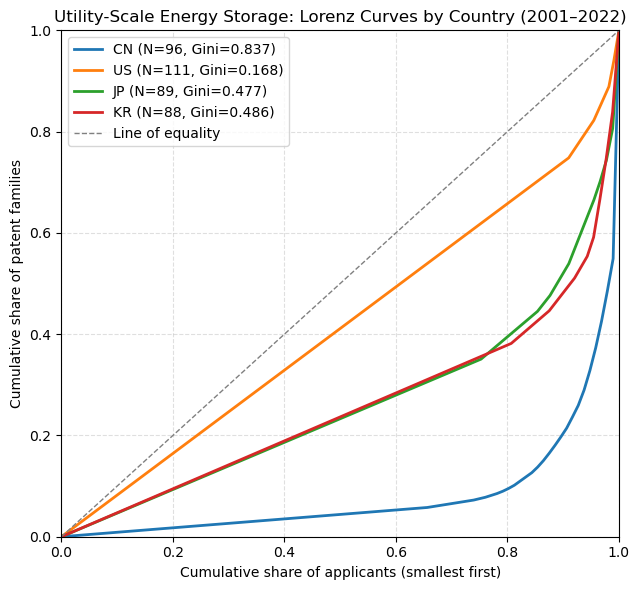

,CR4 (%),CR8 (%),HH,CV,Gini,Lotka L
country,,,,,,
CN,1,1,1,1,1,1
JP,4,4,3,2,3,2
KR,3,3,4,3,2,3
US,6,6,6,6,6,6
DE,5,5,5,4,5,5
CH,2,2,2,5,4,4


,CR4 (%),CR8 (%),HH,CV,Gini,Lotka L
CR4 (%),1.000,1.000,0.867,0.467,0.733,0.600
CR8 (%),1.000,1.000,0.867,0.467,0.733,0.600
HH,0.867,0.867,1.000,0.600,0.600,0.733
CV,0.467,0.467,0.600,1.000,0.733,0.867
Gini,0.733,0.733,0.600,0.733,1.000,0.867
Lotka L,0.600,0.600,0.733,0.867,0.867,1.000


In [36]:
from scipy.stats import kendalltau

# 1. Assign a unique primary country to each harmonised applicant in the completed period
complete_valid = complete.copy()
complete_valid["ctry"] = complete_valid["ctry"].replace(r"^\s*$", np.nan, regex=True)

applicant_country = (
    complete_valid.groupby("applicant")["ctry"]
    .agg(lambda s: s.dropna().mode().iloc[0] if not s.dropna().empty else np.nan)
)
applicant_families = complete_valid.groupby("applicant")["unit_id"].nunique()

appl_geo = (
    pd.DataFrame({"country": applicant_country, "families": applicant_families})
    .dropna(subset=["country"])
)

# 2. Descriptive summary by country (applicants, unique families, assignments, and distribution stats)
unique_families_by_ctry = (
    complete_valid.dropna(subset=["ctry"])
    .groupby("ctry")["unit_id"]
    .nunique()
)

country_summary = (
    appl_geo.groupby("country")
    .agg(
        applicants=("families", "count"),
        applicant_family_assignments=("families", "sum"),
        mean_families_per_applicant=("families", "mean"),
        median_families_per_applicant=("families", "median"),
        min_families=("families", "min"),
        max_families=("families", "max"),
    )
    .sort_values("applicant_family_assignments", ascending=False)
)

country_summary.insert(1, "unique_families", unique_families_by_ctry)
country_summary["share_of_assignments (%)"] = (
    country_summary["applicant_family_assignments"] / country_summary["applicant_family_assignments"].sum() * 100
)

# Display top 10 countries plus a Total row
top_country_table = country_summary.head(10).copy()
top_country_table.loc["Total (all with country)"] = [
    len(appl_geo),
    complete_valid.dropna(subset=["ctry"])["unit_id"].nunique(),
    appl_geo["families"].sum(),
    appl_geo["families"].mean(),
    appl_geo["families"].median(),
    appl_geo["families"].min(),
    appl_geo["families"].max(),
    100.0,
]
display(top_country_table.round(2))

# 3. Concentration measures by country (for countries with enough applicants, e.g., >= 15)
MIN_APPL_PER_COUNTRY = 15
eligible_countries = country_summary[country_summary["applicants"] >= MIN_APPL_PER_COUNTRY].index

conc_by_country = pd.DataFrame(
    {
        ctry: six_measures(appl_geo[appl_geo["country"] == ctry]["families"].to_numpy())
        for ctry in eligible_countries
    }
).T
conc_by_country = conc_by_country.loc[eligible_countries]  # keep sorted by volume
display(conc_by_country.round(3))

# 4. Lorenz curve for the leading country (China, CN) vs. major peers
top_countries_lorenz = [c for c in ["CN", "US", "JP", "KR", "DE"] if c in appl_geo["country"].unique()][:4]

fig, ax = plt.subplots(figsize=(6.5, 6))
for ctry in top_countries_lorenz:
    vals = appl_geo[appl_geo["country"] == ctry]["families"].to_numpy()
    x_f, y_p = lorenz_curve(vals)
    ax.plot(x_f, y_p, lw=2, label=f"{ctry} (N={len(vals)}, Gini={gini(vals):.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="grey", lw=1, label="Line of equality")
ax.set(
    title=f"{SECTOR_NAME}: Lorenz Curves by Country ({YEAR_MIN}–{LAST_COMPLETE_YEAR})",
    xlabel="Cumulative share of applicants (smallest first)",
    ylabel="Cumulative share of patent families",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend(loc="upper left")
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# 5. Country rankings across measures and Kendall's tau-b correlation (two dimensions of concentration)
measures_cols = ["CR4 (%)", "CR8 (%)", "HH", "CV", "Gini", "Lotka L"]
rank_df = conc_by_country[measures_cols].dropna().copy()
# Note: for Lotka L (negative slope), steeper negative values mean higher concentration/inequality, or rank raw values consistently
rankings = rank_df.rank(ascending=False)
display(rankings.astype(int))

tau_matrix = pd.DataFrame(index=measures_cols, columns=measures_cols, dtype=float)
for m1 in measures_cols:
    for m2 in measures_cols:
        tau, _ = kendalltau(rank_df[m1], rank_df[m2])
        tau_matrix.loc[m1, m2] = tau

display(tau_matrix.round(3))

### 5.4 Country-Level Concentration and the Two Dimensions of Concentration

* **Geographic distribution and skewness across countries (`2001–2022`):** Across the **567** harmonised applicants with an explicit country code in `complete` (**1,847** applicant-family assignments across **564** tagged families; global mean **3.26**, median **1.0**, max **492.0**), **China (`CN`)** dominates with **1,091** assignments (**59.07%**) across **96** applicants. While the median is **1.0** in every country, China's mean reaches **11.36** families per applicant (max **492.0**), compared to **2.15** in **Japan (`JP`)** (89 applicants, 191 assignments, **10.34%**, max **37.0**), **2.11** in **South Korea (`KR`)** (88 applicants, 186 assignments, **10.07%**, max **30.0**), **1.22** in the **United States (`US`)** (111 applicants, 135 assignments, **7.31%**, max **8.0**), and **1.47** in **Germany (`DE`)** (70 applicants, 103 assignments, **5.58%**, max **15.0**).
* **Contrasting internal market structures (Lorenz curves):** Across major countries (`>= 15` applicants), **China (`CN`)** ranks first on every concentration and inequality metric (**CR4 = 62.695%**, **CR8 = 76.352%**, **HH = 0.221**, **1/HH = 4.526**, **Gini = 0.837**), with its Lorenz curve showing that the bottom 80% of Chinese applicants account for under 10% of patent families[cite: . By contrast, the **United States (`US`)** exhibits a highly fragmented base (**111** applicants averaging ~1.2 families each) and ranks lowest across all metrics (**CR4 = 15.556%**, **HH = 0.014**, **Gini = 0.168**), while **Japan (`JP`)** and **South Korea (`KR`)** display nearly identical intermediate profiles (**Gini = 0.477** and **0.486**; **HH = 0.053**).
* **Rankings and Kendall's $\tau_b$ — two distinct dimensions of concentration:** Pairwise rank correlations across countries confirm that the six indicators capture two related but distinct dimensions:
  1. **Top-share / market concentration (`CR4`, `CR8`, `HH`):** Strongly correlated internally ($\tau_b = 1.000$ between `CR4` and `CR8`; $\tau_b = 0.867$ with `HH`), reflecting how much activity is held by the largest few entities relative to total national volume.
  2. **Distributional inequality / tail skewness (`CV`, `Gini`, `Lotka L`):** Strongly correlated among themselves ($\tau_b = 0.867$ between `CV`/`Gini` and `Lotka L`; $\tau_b = 0.733$ between `CV` and `Gini`), capturing dispersion between small and large patentees.
  * Cross-dimension correlations are notably lower (e.g., $\tau_b = 0.467$ between `CR4`/`CR8` and `CV`, and $\tau_b = 0.600$ between `HH` and `Gini`). **Switzerland (`CH`)** illustrates this divergence clearly: because its pool is small (`15` applicants), it ranks **2nd** in top-share concentration (`CR4 = 55.556%`, `HH = 0.106`) yet only **5th** in `CV` (`0.791`) and **4th** in `Gini` (`0.341`).

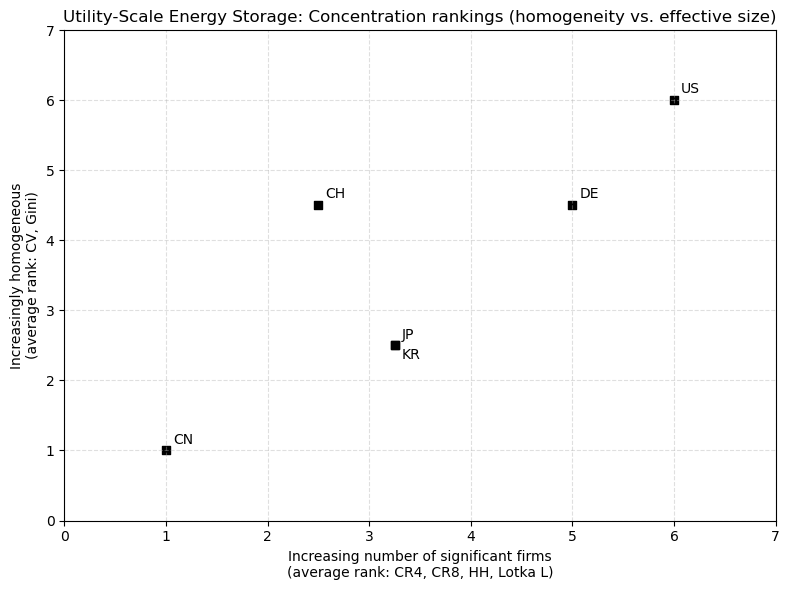

In [35]:
# Scatter plot of average country ranks across the two dimensions of concentration
x = rankings[["CR4 (%)", "CR8 (%)", "HH", "Lotka L"]].mean(axis=1)
y = rankings[["CV", "Gini"]].mean(axis=1)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(x, y, marker="s", color="black")
for country in rankings.index:
    offset = (5, -10) if country == "KR" else (5, 5)
    ax.annotate(country, (x[country], y[country]), xytext=offset, textcoords="offset points")

ax.set(
    xlim=(0, len(rankings) + 1),
    ylim=(0, len(rankings) + 1),
    title=f"{SECTOR_NAME}: Concentration rankings (homogeneity vs. effective size)",
    xlabel="Increasing number of significant firms\n(average rank: CR4, CR8, HH, Lotka L)",
    ylabel="Increasingly homogeneous\n(average rank: CV, Gini)",
)
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

* **Visualizing the two dimensions (`homogeneity vs. effective size`):** Plotting average ranks along top-share/tail metrics (`CR4`, `CR8`, `HH`, `Lotka L`) against inequality metrics (`CV`, `Gini`) places **China (`CN`)** at `(1.0, 1.0)` (few dominant players, high skewness) and the **United States (`US`)** at `(6.0, 6.0)` (many small, relatively homogeneous applicants), with **Japan (`JP`)** and **South Korea (`KR`)** overlapping at `(3.25, 2.5)` and **Germany (`DE`)** at `(5.0, 4.5)`. **Switzerland (`CH`)** stands off the main diagonal at `(2.5, 4.5)`, visually confirming that small national pools can combine high top-firm concentration with relatively low internal dispersion.